# SFSC 2026 - binary DeepLabV3 with CLAHE and BCE + Dice + boundary loss

**One grayscale input channel. One output logit. No chirality classification, detector, or multiclass training.** This is DeepLabV3-ResNet50, not DeepLabV3+.

The requested objective is implemented exactly at the outer level:

$$L = 1.0 L_{\mathrm{Weighted\ BCE}} + 1.0 L_{\mathrm{Dice}} + 0.2 L_{\mathrm{Boundary}}.$$

The screenshot specifies the coefficients, but not the component definitions. Here, Weighted BCE means positive-class-weighted `BCEWithLogitsLoss`; Dice is soft foreground Dice; Boundary is a **clipped, normalized signed-distance loss with a target-only offset**. The offset makes its minimum zero without changing its gradient. Clipping/normalization and empty-mask handling are explicit implementation choices, not claims about the screenshot. Cell 12 gives the definitions.

### End-to-end pipeline
Original 2048 x 2048 grayscale JPEG -> optional mild full-image CLAHE -> native-resolution training crops -> one-channel DeepLabV3 -> overlapping full-resolution inference -> threshold + connected components -> instance PQ -> compressed COCO-RLE submission.

All filament categories are foreground. A training target combines masks **within one annotation record**, not across different annotators. Repeated annotations of a source image never cross data splits. Individual ground-truth instance masks are retained for PQ evaluation.

**Important limitation:** connected-component labels are instance IDs, not classes. Binary semantic segmentation cannot explicitly distinguish touching instances; it may merge touching filaments or split disconnected ones. A lower loss or higher pixel Dice does not guarantee better PQ. The notebook selects checkpoints and post-processing using full-image development PQ.

The reported historical cascade PQ of 0.435179 is not a guaranteed target this model will exceed. Compare champion and new predictions on identical records with the same scorer. The default new split is not directly comparable to that historical scalar.

### Running
Select an L4 GPU in Colab, run the Drive setup cell, edit Cell 03 if needed, and run cells in order. Do not train on the supplied side-by-side montage or colored annotation overlay. Cells 19 onward train, calibrate, audit, and export. Dependencies and official pretrained weights need internet on first use unless supplied locally.

**Local scoring convention:** global additive PQ, strict IoU > 0.5, maximum-summed-IoU one-to-one assignment. Ambiguous overlap graphs are reported. Hidden-organizer edge-case equivalence is not certified; verify the final CSV with the current organizer self-evaluation notebook. No automatic Kaggle submission is performed.

**Validation status of this deliverable:** see `VALIDATION_REPORT.md` for checks actually executed. No competition training, GPU benchmark, or measured SFSC PQ is bundled.

## Colab setup - L4 GPU and persistent Google Drive

In Colab, select **Runtime -> Change runtime type -> Python 3 -> GPU -> L4**,
then run the cells in order. This first cell mounts your Google Drive using
Colab's browser authorization.

The paths below use our existing `MyDrive/SFSC2026` storage:

- Dataset archive: `data/sfsc2026-data.zip`.
- Extracted dataset: `data/SFSCDataset` (reused across runtimes).
- Checkpoints, training history, target/probability caches, reports and submission:
  `outputs/sfsc_deeplabv3_clahe_v1`.
- Downloaded pretrained weights: `cache/torch`.

If the dataset is already extracted elsewhere on Drive, set `DRIVE_DATA_ROOT`
to that directory. Otherwise this cell extracts the existing Drive ZIP directly
onto Drive. Existing files with the correct size are reused; an interrupted
extraction can be continued by rerunning this cell. No dataset upload is needed.

For a separate experiment, change `DRIVE_OUTPUT_DIR`. To resume an existing run,
set `resume_path` in Cell 03 to `str(DRIVE_OUTPUT_DIR / "last.pt")`; the original
notebook's resume behavior is retained. Training settings are unchanged.


In [1]:
from google.colab import drive
from pathlib import Path
import os
import zipfile

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/SFSC2026")
DRIVE_DATA_ARCHIVE = DRIVE_ROOT / "data" / "sfsc2026-data.zip"
DRIVE_DATA_ROOT = DRIVE_ROOT / "data" / "SFSCDataset"
DRIVE_OUTPUT_DIR = DRIVE_ROOT / "outputs" / "sfsc_deeplabv3_clahe_v1"

# Keep downloaded pretrained weights and package downloads on Drive as well.
os.environ["TORCH_HOME"] = str(DRIVE_ROOT / "cache" / "torch")
os.environ["PIP_CACHE_DIR"] = str(DRIVE_ROOT / "cache" / "pip")
for folder in (DRIVE_OUTPUT_DIR, Path(os.environ["TORCH_HOME"]), Path(os.environ["PIP_CACHE_DIR"])):
    folder.mkdir(parents=True, exist_ok=True)

# Expand our saved archive onto Drive, reusing files on subsequent sessions.
# Point DRIVE_DATA_ROOT at an existing extracted dataset to use that instead.
if DRIVE_DATA_ARCHIVE.is_file():
    DRIVE_DATA_ROOT.mkdir(parents=True, exist_ok=True)
    extracted = 0
    with zipfile.ZipFile(DRIVE_DATA_ARCHIVE) as archive:
        for member in archive.infolist():
            if member.is_dir():
                continue
            target = (DRIVE_DATA_ROOT / member.filename).resolve()
            if not target.is_relative_to(DRIVE_DATA_ROOT.resolve()):
                raise ValueError(f"Archive path escapes the dataset directory: {member.filename}")
            if target.is_file() and target.stat().st_size == member.file_size:
                continue
            archive.extract(member, DRIVE_DATA_ROOT)
            extracted += 1
    print(f"Dataset ready on Drive; extracted {extracted} files, reused the rest.")
elif not DRIVE_DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset not found. Expected {DRIVE_DATA_ARCHIVE}, or set DRIVE_DATA_ROOT "
        "to your existing extracted dataset on Drive."
    )

print("Dataset:", DRIVE_DATA_ROOT)
print("Persistent run directory:", DRIVE_OUTPUT_DIR)


Mounted at /content/drive
Dataset ready on Drive; extracted 0 files, reused the rest.
Dataset: /content/drive/MyDrive/SFSC2026/data/SFSCDataset
Persistent run directory: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3_clahe_v1


## Cell 01 - Install utility dependencies

Keep the runtime's matching PyTorch/Torchvision GPU builds. This cell only installs missing utilities and does not replace CUDA packages. PyTorch >= 2.3 is required for the AMP API used below.

In [2]:
import importlib.util, subprocess, sys
requirements = {
    "numpy": "numpy>=1.24", "pandas": "pandas>=2.0", "PIL": "Pillow>=10",
    "scipy": "scipy>=1.10", "cv2": "opencv-python-headless>=4.8",
    "pycocotools": "pycocotools>=2.0.7", "matplotlib": "matplotlib>=3.7",
    "tqdm": "tqdm>=4.66",
}
missing = [v for k, v in requirements.items() if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
try:
    import torch, torchvision
except Exception as exc:
    raise RuntimeError("Install matching PyTorch/Torchvision GPU builds and restart the kernel.") from exc
assert tuple(int(x) for x in torch.__version__.split("+")[0].split(".")[:2]) >= (2, 3)
print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu130 Torchvision: 0.26.0+cu130


## Cell 02 - Imports and reproducibility helpers

Record environment versions with every run. Crop and augmentation randomness is seeded per sample and epoch; strict CUDA determinism is optional and can reduce speed.

In [3]:
import contextlib, copy, hashlib, json, math, os, platform, random, re, shutil, time, warnings
from collections import defaultdict
from dataclasses import dataclass, asdict
from functools import lru_cache
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from pycocotools import mask as mask_api
from tqdm.auto import tqdm
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cv2.setNumThreads(0)

def seed_everything(seed, deterministic=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not deterministic
    torch.backends.cudnn.deterministic = deterministic
    torch.use_deterministic_algorithms(deterministic, warn_only=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def object_hash(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, separators=(",", ":")).encode()).hexdigest()

def write_json(path, data):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(data, indent=2, allow_nan=False))
    temp.replace(path)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))
    print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

Device: cuda
NVIDIA L4
VRAM GiB: 22.03


## Cell 03 - Configuration - edit here

These are starting settings, not validated SFSC optima. Default effective batch = 2 x 4 = 8; this does not substitute for BatchNorm's actual micro-batch, so pretrained BatchNorm running statistics are frozen. An epoch is 256 micro-batches of sampled crops, not an exhaustive pass through all full frames.

CLAHE is a training augmentation with probability 0.5. It operates on a **full 2048-pixel frame before cropping**, so its 8 x 8 grid has the same spatial scale as optional inference CLAHE. At inference the notebook compares raw input and fixed CLAHE on development data only, then freezes one choice. No random augmentations are applied to development, holdout, or test images.

For an existing split, supply a CSV with columns `file_name,split` and values `train`, `dev`, `holdout`. All filenames must be included once. A legacy date-mixed split requires an explicit `group_by_date=False` and has weaker temporal separation.

In [4]:
@dataclass
class Config:
    data_root: str | None = str(DRIVE_DATA_ROOT)
    output_dir: str = str(DRIVE_OUTPUT_DIR)
    split_csv: str | None = None
    group_by_date: bool = True
    dev_fraction: float = 0.15
    holdout_fraction: float = 0.15
    seed: int = 20261010
    deterministic: bool = False
    expected_shape: tuple = (2048, 2048)
    crop_size: int = 512
    batch_size: int = 2
    accumulation: int = 4
    steps_per_epoch: int = 256
    epochs: int = 40
    workers: int = 2
    positive_crop_probability: float = 0.65
    clahe_probability: float = 0.5
    clahe_clip_range: tuple = (1.5, 2.5)
    clahe_grid: tuple = (8, 8)  # NUMBER of histogram tiles, not pixels per tile
    inference_clahe_clip: float = 2.0
    intensity_probability: float = 0.3
    brightness_delta: float = 0.03
    contrast_range: tuple = (0.95, 1.05)
    gray_mean: float = 0.5
    gray_std: float = 0.25
    positive_bce_weight: float = 3.0  # distinct from the outer BCE coefficient of 1.0
    bce_coefficient: float = 1.0
    dice_coefficient: float = 1.0
    boundary_coefficient: float = 0.2
    boundary_radius: float = 16.0  # native-pixel distance clipping and normalization
    pretrained: bool = True
    pretrained_weights_path: str | None = None  # official torchvision 21-class state_dict, offline
    backbone_lr: float = 1e-4
    head_lr: float = 5e-4
    weight_decay: float = 1e-4
    warmup_epochs: int = 2
    amp: bool = True
    ema_decay: float = 0.99
    eval_every: int = 4
    patience_evaluations: int = 6
    inference_tile: int = 512
    inference_stride: int = 384
    inference_batch: int = 4
    selection_threshold: float = 0.5
    selection_minimum_area: int = 32
    thresholds: tuple = (0.3, 0.4, 0.5, 0.6, 0.7)
    minimum_areas: tuple = (1, 16, 32, 64, 128)
    connectivity: int = 8
    inference_modes: tuple = ("raw", "clahe")
    tta: tuple = ("identity",)  # optional true passes: ("identity", "hflip", "vflip")
    do_train: bool = True
    allow_cpu_training: bool = False
    resume_path: str | None = None  # own trusted last.pt only
    champion_predictions_json: str | None = None
    save_test_probabilities: bool = False

CFG = Config()
assert CFG.batch_size > 0 and CFG.accumulation > 0 and CFG.steps_per_epoch > 0 and CFG.epochs > 0
assert CFG.workers >= 0 and CFG.eval_every > 0 and CFG.inference_batch > 0
assert 0 <= CFG.clahe_probability <= 1 and 0 <= CFG.positive_crop_probability <= 1
assert CFG.dev_fraction > 0 and CFG.holdout_fraction > 0 and CFG.dev_fraction + CFG.holdout_fraction < 1
assert CFG.thresholds and all(0 < t < 1 for t in CFG.thresholds)
assert CFG.minimum_areas and all(isinstance(a, int) and a >= 1 for a in CFG.minimum_areas)
assert CFG.inference_modes and set(CFG.inference_modes) <= {"raw", "clahe"}
assert CFG.tta and set(CFG.tta) <= {"identity", "hflip", "vflip", "rot90"}
assert CFG.steps_per_epoch % CFG.accumulation == 0
assert 0 < CFG.inference_stride <= CFG.inference_tile
assert CFG.crop_size % 8 == 0 and CFG.inference_tile % 8 == 0
assert CFG.boundary_radius > 0 and CFG.gray_std > 0
assert (CFG.bce_coefficient, CFG.dice_coefficient, CFG.boundary_coefficient) == (1.0, 1.0, 0.2)
assert CFG.connectivity in (4, 8)
seed_everything(CFG.seed, CFG.deterministic)
AMP_ENABLED = CFG.amp and DEVICE.type == "cuda"
RUN = Path(CFG.output_dir).expanduser().resolve()
RUN.mkdir(parents=True, exist_ok=True)
print("Run:", RUN, "Effective batch:", CFG.batch_size * CFG.accumulation)
print("Loss: 1.0 WeightedBCE + 1.0 Dice + 0.2 Boundary")

Run: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3_clahe_v1 Effective batch: 8
Loss: 1.0 WeightedBCE + 1.0 Dice + 0.2 Boundary


## Cell 04 - Locate the dataset and audit original JPEGs

Dataset discovery searches the persistent Drive dataset directory configured above. It refuses ambiguous dataset matches. Original dimensions are checked; there is no full-image shrinking. Exact-byte duplicate images and repeated annotations are grouped together during splitting.

In [6]:

import os
import json
import shutil
import zipfile
import hashlib
from pathlib import Path
from collections import defaultdict
from PIL import Image
import numpy as np
from tqdm.auto import tqdm

# Use local Colab storage for images instead of reading
# directly from Google Drive during training.
ANNOTATION_NAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
LOCAL_DATA_ROOT = Path("/content/sfsc_dataset_local")
LOCAL_ARCHIVE = Path("/content/sfsc2026-data-local.zip")


def locate_dataset(root):
    root = Path(root).expanduser()

    hits = sorted(
        root.rglob(ANNOTATION_NAME)
    ) if root.is_dir() else []

    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected one annotation JSON under {root}; found {len(hits)}."
        )

    ann = hits[0]
    train_dir = ann.parent / "train_images"
    test_dir = ann.parent.parent / "test" / "test_images"

    if not train_dir.is_dir() or not test_dir.is_dir():
        raise FileNotFoundError(
            "Expected train/train_images and test/test_images."
        )

    return ann, train_dir, test_dir


def dataset_is_ready(root):
    try:
        ann, train_dir, test_dir = locate_dataset(root)
        return (
            any(train_dir.glob("*.jp*g"))
            and any(test_dir.glob("*.jp*g"))
        )
    except (OSError, FileNotFoundError):
        return False


def ensure_drive_connected():
    from google.colab import drive

    try:
        with open(DRIVE_DATA_ARCHIVE, "rb") as f:
            f.read(1)
        return
    except (OSError, FileNotFoundError):
        print("Reconnecting Google Drive...")

    try:
        drive.mount("/content/drive", force_remount=True)
        if not DRIVE_DATA_ARCHIVE.is_file() and not DRIVE_DATA_ROOT.is_dir():
            raise FileNotFoundError("Dataset unavailable after remount.")
    except Exception as e:
        raise RuntimeError(
            "Google Drive connection failed. Reconnect Drive "
            "or restart the Colab runtime, then rerun this cell."
        ) from e


# Step 1: Stage the dataset locally.
if not dataset_is_ready(LOCAL_DATA_ROOT):
    ensure_drive_connected()

    if DRIVE_DATA_ARCHIVE.is_file():
        archive_size = DRIVE_DATA_ARCHIVE.stat().st_size

        # Reuse previously copied local archive when possible.
        if (
            not LOCAL_ARCHIVE.exists()
            or LOCAL_ARCHIVE.stat().st_size != archive_size
        ):
            print("Copying dataset ZIP from Drive to local Colab storage...")

            temp_archive = LOCAL_ARCHIVE.with_suffix(".part")
            shutil.copyfile(DRIVE_DATA_ARCHIVE, temp_archive)
            os.replace(temp_archive, LOCAL_ARCHIVE)

        LOCAL_DATA_ROOT.mkdir(parents=True, exist_ok=True)

        print("Extracting dataset locally...")

        with zipfile.ZipFile(LOCAL_ARCHIVE) as z:
            members = [m for m in z.infolist() if not m.is_dir()]

            root_resolved = LOCAL_DATA_ROOT.resolve()

            for member in tqdm(members, desc="Extract dataset"):
                dest = (LOCAL_DATA_ROOT / member.filename).resolve()

                if not dest.is_relative_to(root_resolved):
                    raise ValueError("Unsafe ZIP path.")

                if dest.is_file() and dest.stat().st_size == member.file_size:
                    continue

                z.extract(member, LOCAL_DATA_ROOT)

    elif DRIVE_DATA_ROOT.is_dir():
        print("Copying extracted dataset to local Colab storage...")
        shutil.copytree(
            DRIVE_DATA_ROOT,
            LOCAL_DATA_ROOT,
            dirs_exist_ok=True,
        )
    else:
        raise FileNotFoundError("Dataset ZIP or extracted dataset not found.")

if not dataset_is_ready(LOCAL_DATA_ROOT):
    raise RuntimeError("Local dataset staging is incomplete.")

# Step 2: Point the notebook to LOCAL data.
CFG.data_root = str(LOCAL_DATA_ROOT)

ANN_PATH, TRAIN_DIR, TEST_DIR = locate_dataset(CFG.data_root)


def image_files(folder):
    return sorted(
        p for p in Path(folder).iterdir()
        if p.suffix.lower() in (".jpg", ".jpeg")
    )


def read_gray(path):
    path = Path(path)

    try:
        with Image.open(path) as im:
            im.load()

            if im.mode not in ("L", "RGB"):
                raise ValueError(f"Unexpected image mode: {im.mode}")

            if im.mode == "RGB":
                rgb = np.asarray(im, dtype=np.int16)

                if (
                    np.max(np.abs(rgb[..., 0] - rgb[..., 1])) > 2
                    or np.max(np.abs(rgb[..., 0] - rgb[..., 2])) > 2
                ):
                    raise ValueError(
                        f"Non-grayscale image detected: {path}"
                    )

            return np.asarray(
                im.convert("L"),
                dtype=np.uint8,
            ).copy()

    except OSError as exc:
        raise OSError(
            f"Cannot read image: {path}. "
            "Check local dataset storage and Colab runtime."
        ) from exc


# Step 3: Rebuild dataset references using local paths.
RAW = json.loads(ANN_PATH.read_text())
ANN_SHA = file_sha256(ANN_PATH)

TRAIN_PATHS = {
    p.name: p for p in image_files(TRAIN_DIR)
}

TEST_PATHS = {
    p.name: p for p in image_files(TEST_DIR)
}

assert TRAIN_PATHS and TEST_PATHS, "Image directory is empty."

STEM_TO_FILES = defaultdict(list)

for name in TRAIN_PATHS:
    STEM_TO_FILES[Path(name).stem].append(name)


def canonical_filename(value):
    name = Path(str(value)).name

    if name in TRAIN_PATHS:
        return name

    candidates = STEM_TO_FILES.get(Path(name).stem, [])

    if len(candidates) == 1:
        return candidates[0]

    raise ValueError(
        f"Missing or ambiguous source image: {value}"
    )


# Step 4: Validate the local dataset.
FILE_HASHES = {}

for name, path in tqdm(
    TRAIN_PATHS.items(),
    desc="Validate local JPEGs",
):
    image = read_gray(path)

    if image.shape != tuple(CFG.expected_shape):
        raise ValueError(
            f"{name}: {image.shape}, expected {CFG.expected_shape}"
        )

    FILE_HASHES[name] = file_sha256(path)

print("Dataset ready on LOCAL Colab storage.")
print("Training images:", len(TRAIN_PATHS))
print("Test images:", len(TEST_PATHS))
print("Local root:", LOCAL_DATA_ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Copying dataset ZIP from Drive to local Colab storage...
Extracting dataset locally...


Extract dataset:   0%|          | 0/888 [00:00<?, ?it/s]

Validate local JPEGs:   0%|          | 0/707 [00:00<?, ?it/s]

Dataset ready on LOCAL Colab storage.
Training images: 707
Test images: 180
Local root: /content/sfsc_dataset_local
GPU: NVIDIA L4


## Cell 05 - Decode polygon/RLE annotations and define distance targets

The dataset description uses both polygon and RLE terminology. This decoder accepts COCO polygon lists, uncompressed RLE dictionaries, and compressed RLE dictionaries. It does not infer masks from bounding boxes or spines.

The signed distance is negative inside foreground and positive outside. It is computed on the full binary annotation record before cropping, avoiding artificial boundaries at training-crop edges. Values are clipped at 16 native pixels and divided by 16. Empty/full masks have explicit constant targets.

In [7]:
def native_rle(rle):
    counts = rle["counts"]
    if isinstance(counts, str):
        counts = counts.encode("ascii")
    return {"size": [int(x) for x in rle["size"]], "counts": counts}

def json_rle(rle):
    counts = rle["counts"]
    return {"size": [int(x) for x in rle["size"]],
            "counts": counts.decode("ascii") if isinstance(counts, bytes) else counts}

def encode_mask(mask):
    a = np.asarray(mask, dtype=np.uint8)
    if a.ndim != 2:
        raise ValueError("Expected a 2D mask")
    return json_rle(mask_api.encode(np.asfortranarray(a)))

def decode_mask(rle):
    a = mask_api.decode(native_rle(rle))
    if a.ndim == 3:
        a = np.any(a, axis=2)
    return a.astype(bool)

def segmentation_to_rle(segmentation, height, width):
    if isinstance(segmentation, dict):
        if list(segmentation.get("size", [height, width])) != [height, width]:
            raise ValueError("RLE dimensions do not match the source JPEG.")
        if isinstance(segmentation.get("counts"), list):
            rle = mask_api.frPyObjects(segmentation, height, width)
        else:
            rle = native_rle({"size": [height, width], "counts": segmentation["counts"]})
    elif isinstance(segmentation, list) and segmentation:
        polygons = segmentation if isinstance(segmentation[0], (list, tuple)) else [segmentation]
        if any(len(p) < 6 or len(p) % 2 for p in polygons):
            raise ValueError("Invalid polygon coordinate list.")
        rle = mask_api.merge(mask_api.frPyObjects(polygons, height, width))
    else:
        raise ValueError("Empty or unsupported segmentation. Inspect the source instead of guessing.")
    out = json_rle(rle)
    if decode_mask(out).shape != (height, width):
        raise ValueError("Decoded mask shape mismatch")
    return out

def signed_distance_target(mask, radius=16.0):
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        return np.ones(mask.shape, np.float32)
    if mask.all():
        return -np.ones(mask.shape, np.float32)
    phi = ndi.distance_transform_edt(~mask) - ndi.distance_transform_edt(mask)
    return (np.clip(phi, -radius, radius) / radius).astype(np.float32)

## Cell 06 - Create per-record binary targets and keep instance ground truth

Cache masks and distance maps in compressed NPZ files. This one-off step can take time; its directory is keyed by annotation hash and boundary radius. All four source categories are combined into foreground within each record, while independent annotators are not unioned together.

Zero-instance records are retained as negative examples. Empty individual instance masks and invalid annotations stop execution rather than being silently dropped. The cache is not a model input at inference.

In [8]:

import os
import pickle
import hashlib
import warnings
import tempfile
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from tqdm.auto import tqdm

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------
CACHE = RUN / "target_cache" / f"{ANN_SHA[:12]}_r{CFG.boundary_radius:g}"
CACHE.mkdir(parents=True, exist_ok=True)

# Limit concurrency to avoid excessive RAM consumption.
CPU_COUNT = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 4)
NUM_WORKERS = min(4, CPU_COUNT)

# True = faster writes, larger files
# False = smaller files, slower initial writes
FAST_CACHE = False

# Prevent OpenCV from oversubscribing CPU threads.
try:
    import cv2
    cv2.setNumThreads(1)
except ImportError:
    pass

# ---------------------------------------------------------
# Index annotations once
# ---------------------------------------------------------
IMAGES_BY_ID = {}
for im in RAW["images"]:
    rid = str(im["id"])
    if rid in IMAGES_BY_ID:
        raise ValueError(f"Duplicate image-record id: {rid}")
    IMAGES_BY_ID[rid] = im

ANNOTATIONS_BY_ID = defaultdict(list)
seen_annotations = set()

for a in RAW["annotations"]:
    aid = str(a["id"])
    rid = str(a["image_id"])

    if aid in seen_annotations or rid not in IMAGES_BY_ID:
        raise ValueError(f"Duplicate annotation or missing image: {aid}, {rid}")

    if int(a.get("iscrowd", 0)) != 0:
        raise ValueError("Unexpected crowd annotation.")

    seen_annotations.add(aid)
    ANNOTATIONS_BY_ID[rid].append(a)

# ---------------------------------------------------------
# Atomic cache writer
# ---------------------------------------------------------
def atomic_write(path, writer):
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=".tmp_")
    os.close(fd)

    try:
        with open(tmp, "wb") as f:
            writer(f)
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)

# ---------------------------------------------------------
# Process a single annotation record
# ---------------------------------------------------------
def process_record(item):
    rid, im = item

    name = canonical_filename(im["file_name"])
    h, w = int(im["height"]), int(im["width"])

    if (h, w) != tuple(CFG.expected_shape):
        raise ValueError(f"Metadata dimensions disagree: {rid}")

    key = hashlib.sha256(rid.encode()).hexdigest()[:24]

    cache_path = CACHE / f"{key}.npz"
    meta_path = CACHE / f"{key}.pkl"

    # FAST PATH: skip decoding and distance calculation.
    if cache_path.exists() and meta_path.exists():
        with open(meta_path, "rb") as f:
            record = pickle.load(f)
        record["cache"] = str(cache_path)
        return record

    union = np.zeros((h, w), dtype=np.bool_)
    instances = []
    points = []

    seed = int(hashlib.sha256(rid.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)

    # -----------------------------------------------------
    # Decode annotations
    # -----------------------------------------------------
    for a in ANNOTATIONS_BY_ID[rid]:
        rle = segmentation_to_rle(a["segmentation"], h, w)
        mask = decode_mask(rle).astype(bool, copy=False)

        if not mask.any():
            raise ValueError(f"Empty filament instance: {a['id']}")

        np.logical_or(union, mask, out=union)
        instances.append(rle)

        # Sample foreground pixels without creating
        # separate full-size X/Y coordinate arrays.
        flat = np.flatnonzero(mask)
        n = min(32, flat.size)

        selected = rng.choice(flat, size=n, replace=False)

        ys = selected // w
        xs = selected % w

        points.append(np.column_stack((ys, xs)).tolist())

    # -----------------------------------------------------
    # Generate expensive targets only when missing
    # -----------------------------------------------------
    if not cache_path.exists():
        distance = signed_distance_target(
            union, CFG.boundary_radius
        )

        save_fn = np.savez if FAST_CACHE else np.savez_compressed

        atomic_write(
            cache_path,
            lambda f: save_fn(
                f,
                mask=union.astype(np.uint8),
                distance=distance.astype(np.float16),
            ),
        )

    record = {
        "id": rid,
        "file_name": name,
        "instances": instances,
        "sample_points": points,
        "cache": str(cache_path),
        "foreground_pixels": int(union.sum()),
    }

    # Cache record metadata to avoid future RLE decoding.
    # Load pickle files only from this trusted local cache.
    atomic_write(
        meta_path,
        lambda f: pickle.dump(
            record, f, protocol=pickle.HIGHEST_PROTOCOL
        ),
    )

    return record

# ---------------------------------------------------------
# Parallel processing
# ---------------------------------------------------------
items = list(IMAGES_BY_ID.items())

print(f"Processing {len(items)} records with {NUM_WORKERS} workers")

with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
    RECORDS = list(
        tqdm(
            executor.map(process_record, items),
            total=len(items),
            desc="Building binary supervision",
        )
    )

# ---------------------------------------------------------
# Build indexes
# ---------------------------------------------------------
RECORDS_BY_FILE = defaultdict(list)

for r in RECORDS:
    RECORDS_BY_FILE[r["file_name"]].append(r)

UNIQUE_FILES = sorted(RECORDS_BY_FILE)

if len({Path(n).stem for n in UNIQUE_FILES}) != len(UNIQUE_FILES):
    raise ValueError("Duplicate annotated image stems.")

unused = sorted(set(TRAIN_PATHS) - set(UNIQUE_FILES))

if unused:
    warnings.warn(
        f"{len(unused)} JPEGs lack image records."
    )

total_instances = sum(len(r["instances"]) for r in RECORDS)

write_json(
    RUN / "dataset_summary.json",
    {
        "annotation_sha256": ANN_SHA,
        "unique_files": len(UNIQUE_FILES),
        "records": len(RECORDS),
        "instances": total_instances,
        "unannotated_files": unused,
    },
)

print(
    f"Complete | Records: {len(RECORDS)} "
    f"| Instances: {total_instances} "
    f"| Workers: {NUM_WORKERS}"
)

Processing 1154 records with 4 workers


Building binary supervision:   0%|          | 0/1154 [00:00<?, ?it/s]

Complete | Records: 1154 | Instances: 8199 | Workers: 4


## Cell 07 - Grouped train / development / holdout split

The default split groups all observations from the same capture date, and merges groups containing exact-byte duplicate JPEGs. All annotation records of one filename remain together. This does not guarantee independence between neighboring dates, and it does not undo earlier research exposure.

Development data selects checkpoints, thresholds, minimum areas and the deterministic preprocessing mode. Holdout data is evaluated only after those choices are frozen. To compare against the champion, supply the intended split and its predictions instead of comparing scalar scores from different splits.

In [10]:
def make_split(names, file_hashes, cfg):
    parent = {n: n for n in names}
    def find(n):
        while parent[n] != n:
            parent[n] = parent[parent[n]]; n = parent[n]
        return n
    def union(a, b):
        a, b = find(a), find(b)
        if a != b: parent[b] = a
    seen_date, seen_hash = {}, {}
    for name in names:
        if cfg.group_by_date:
            match = re.match(r"^(\d{8})\d{6}[A-Za-z]{2}$", Path(name).stem)
            if not match:
                raise ValueError(f"Cannot parse capture date: {name}")
            date = match.group(1)
            if date in seen_date: union(name, seen_date[date])
            seen_date[date] = name
        key = file_hashes[name]
        if key in seen_hash: union(name, seen_hash[key])
        seen_hash[key] = name
    groups = {n: find(n) for n in names}
    if cfg.split_csv:
        frame = pd.read_csv(cfg.split_csv, dtype=str)
        if not {"file_name", "split"}.issubset(frame.columns):
            raise ValueError("Split CSV needs file_name,split columns.")
        frame["file_name"] = frame["file_name"].map(canonical_filename)
        if frame.file_name.duplicated().any() or set(frame.file_name) != set(names):
            raise ValueError("Split CSV must contain every annotated filename exactly once.")
        if set(frame.split) != {"train", "dev", "holdout"}:
            raise ValueError("Split labels must be train, dev, holdout.")
        assignments = dict(zip(frame.file_name, frame.split))
    else:
        unique_groups = sorted(set(groups.values()))
        if len(unique_groups) < 7:
            raise ValueError("Too few independent groups; supply an explicit three-way split.")
        rng = np.random.default_rng(cfg.seed); rng.shuffle(unique_groups)
        nh = max(1, round(len(unique_groups) * cfg.holdout_fraction))
        nd = max(1, round(len(unique_groups) * cfg.dev_fraction))
        assert nh + nd < len(unique_groups)
        assignments_by_group = {g: ("holdout" if i < nh else "dev" if i < nh + nd else "train")
                                for i, g in enumerate(unique_groups)}
        assignments = {n: assignments_by_group[groups[n]] for n in names}
    frame = pd.DataFrame([{"file_name": n, "split": assignments[n], "group": groups[n]} for n in names])
    if frame.groupby("group").split.nunique().max() > 1:
        raise ValueError("A date or exact duplicate crosses splits. Fix the manifest/grouping policy.")
    return frame.sort_values("file_name").reset_index(drop=True)

SPLIT = make_split(UNIQUE_FILES, FILE_HASHES, CFG)
SPLIT.to_csv(RUN / "split.csv", index=False)
SPLIT_SHA = object_hash(SPLIT.to_dict("records"))
FILES = {s: SPLIT.loc[SPLIT.split == s, "file_name"].tolist() for s in ("train", "dev", "holdout")}
TRAIN_RECORDS = [r for n in FILES["train"] for r in RECORDS_BY_FILE[n]]
for s, names in FILES.items():
    print(s, "files:", len(names), "records:", sum(len(RECORDS_BY_FILE[n]) for n in names))
train_fg = sum(r["foreground_pixels"] for r in TRAIN_RECORDS)
print("Full-frame train foreground fraction:", train_fg / (len(TRAIN_RECORDS) * np.prod(CFG.expected_shape)))
print("BCE positive weight (fixed starting choice):", CFG.positive_bce_weight)

train files: 498 records: 828
dev files: 106 records: 152
holdout files: 103 records: 174
Full-frame train foreground fraction: 0.003483854918088314
BCE positive weight (fixed starting choice): 3.0


## Cell 08 - CLAHE, light augmentation and crop dataset

Training CLAHE probability is 0.5, with clip limit sampled from [1.5, 2.5] and an 8 x 8 histogram grid on the full source frame. Background/foreground labels are untouched. Native crops, flips and exact 90-degree rotations preserve mask alignment without interpolation. Mild brightness/contrast is optional; there is no RGB color jitter, resizing, elastic deformation, mosaic, or cutout.

Positive crops choose a pixel from a randomly selected annotated instance; remaining crops are uniform random crops, not forced-empty negatives. Both records and their instances are sampled without validation information. Distance maps receive exactly the same geometric transforms as masks.

In [14]:

from functools import lru_cache
from pathlib import Path

@lru_cache(maxsize=8)
def cached_gray(path):
    return read_gray(path)


@lru_cache(maxsize=8)
def cached_target(cache_path):
    path = Path(cache_path)
    prefix = str(path)

    # Old records store paths ending in .npz.
    # New records store the prefix without .npz.
    if prefix.endswith(".npz"):
        prefix = prefix[:-4]

    mask_path = Path(prefix + "_mask.npy")
    distance_path = Path(prefix + "_distance.npy")

    # Prefer the optimized memory-mapped cache.
    if mask_path.is_file() and distance_path.is_file():
        mask = np.load(
            mask_path,
            mmap_mode="r",
            allow_pickle=False,
        )
        distance = np.load(
            distance_path,
            mmap_mode="r",
            allow_pickle=False,
        )
        return mask, distance

    # Backward compatibility with old compressed targets.
    legacy_path = Path(prefix + ".npz")

    if legacy_path.is_file():
        with np.load(legacy_path, allow_pickle=False) as data:
            mask = data["mask"].astype(np.float32)
            distance = data["distance"].astype(np.float32)
        return mask, distance

    raise FileNotFoundError(
        f"Target cache not found for {cache_path}\n"
        f"Checked:\n"
        f"  {mask_path}\n"
        f"  {distance_path}\n"
        f"  {legacy_path}\n"
        "If these files are missing, rerun Cell 06 to rebuild the targets."
    )


def apply_clahe(image, clip_limit=2.0, grid=(8, 8)):
    if image.dtype != np.uint8 or image.ndim != 2:
        raise ValueError("CLAHE requires grayscale uint8.")

    return cv2.createCLAHE(
        clipLimit=float(clip_limit),
        tileGridSize=tuple(grid),
    ).apply(image)


def prepare_full_image(image, mode, cfg):
    if mode == "raw":
        return image
    if mode == "clahe":
        return apply_clahe(
            image,
            cfg.inference_clahe_clip,
            cfg.clahe_grid,
        )
    raise ValueError(f"Unknown preprocessing mode: {mode}")


# Keep the existing FilamentCrops class from Cell 08.
# This cell only needs to replace the cached_target,
# cached_gray, apply_clahe, and prepare_full_image
# definitions above. Do not remove your FilamentCrops class.

## Cell 09 - Inspect the supervision and CLAHE

Inspect training data only. The grayscale image and binary mask must align; colored rectangles or class IDs must never appear in the model input. CLAHE's strength is a configurable augmentation choice, not a measured PQ gain.

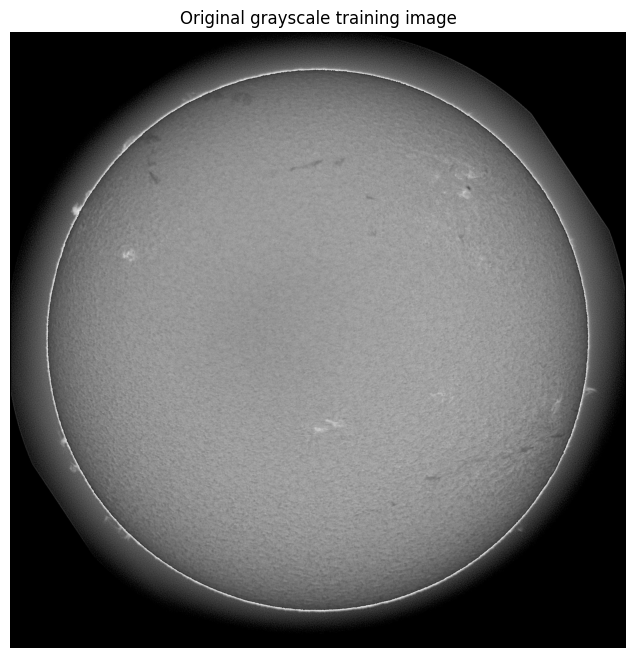

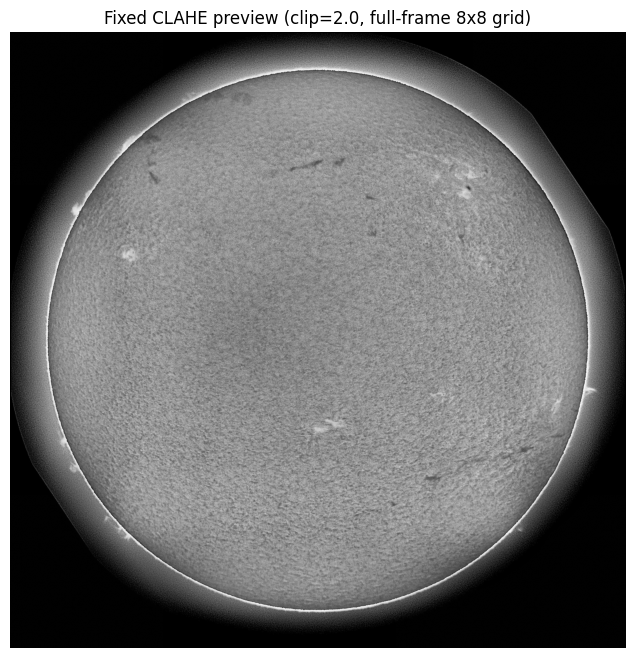

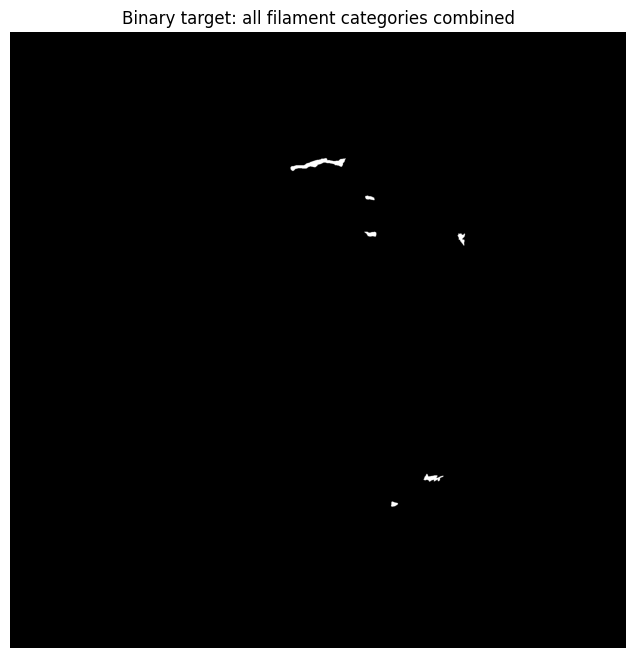

Crop: (1, 512, 512) Mask values: [0.0, 1.0]
Distance range: -0.400146484375 1.0


In [15]:
example = TRAIN_RECORDS[0]
example_image = read_gray(TRAIN_PATHS[example["file_name"]])
example_mask, _ = cached_target(example["cache"])
for title, arr in [("Original grayscale training image", example_image),
                   ("Fixed CLAHE preview (clip=2.0, full-frame 8x8 grid)", apply_clahe(example_image, 2.0, CFG.clahe_grid)),
                   ("Binary target: all filament categories combined", example_mask)]:
    plt.figure(figsize=(8, 8)); plt.imshow(arr, cmap="gray"); plt.title(title); plt.axis("off"); plt.show()
sample = TRAIN_DATASET[0]
print("Crop:", tuple(sample["image"].shape), "Mask values:", torch.unique(sample["mask"]).tolist())
print("Distance range:", float(sample["distance"].min()), float(sample["distance"].max()))

## Cell 10 - Data loader

Workers are recreated each epoch so they see the new deterministic epoch seed. On local notebook environments with multiprocessing issues, set `workers=0`. CLAHE is deliberately limited to one OpenCV thread per worker.

In [16]:

def initialize_worker(worker_id):
    cv2.setNumThreads(1)
    np.random.seed(torch.initial_seed() % (2**32))


def make_train_loader(dataset, cfg):
    kwargs = {
        "dataset": dataset,
        "batch_size": cfg.batch_size,
        "shuffle": False,
        "num_workers": cfg.workers,
        "pin_memory": DEVICE.type == "cuda",
        "drop_last": True,
        "worker_init_fn": initialize_worker,
    }

    if cfg.workers > 0:
        kwargs.update({
            "persistent_workers": True,
            "prefetch_factor": 2,
        })

    return DataLoader(**kwargs)


TRAIN_LOADER = make_train_loader(TRAIN_DATASET, CFG)

print(
    "Micro-batches per epoch:", len(TRAIN_LOADER),
    "Workers:", CFG.workers,
)


Micro-batches per epoch: 256 Workers: 2


## Cell 11 - One-channel DeepLabV3-ResNet50

Load torchvision's pretrained DeepLabV3 weights, then replace the first convolution with a one-channel convolution and the final classifier with one logit. The input convolution is initialized by summing its RGB kernels, preserving its response to three identical standardized channels; this does not claim equivalence to channel-specific ImageNet normalization.

The original torchvision ResNet implementation uses output stride 8. Its auxiliary classifier is removed. Pretrained BatchNorm statistics are frozen, while affine parameters remain trainable. No pretrained transform that shrinks an image to 520 pixels is used. The model never receives RGB data.

In [17]:
def build_model(cfg, load_pretrained=True):
    use_weights = load_pretrained and cfg.pretrained and not cfg.pretrained_weights_path
    net = deeplabv3_resnet50(
        weights=DeepLabV3_ResNet50_Weights.DEFAULT if use_weights else None,
        weights_backbone=None, num_classes=21, aux_loss=True)
    if load_pretrained and cfg.pretrained_weights_path:
        state = torch.load(cfg.pretrained_weights_path, map_location="cpu", weights_only=True)
        net.load_state_dict(state, strict=True)
    old = net.backbone.conv1
    new = nn.Conv2d(1, old.out_channels, kernel_size=old.kernel_size, stride=old.stride,
                    padding=old.padding, dilation=old.dilation, bias=False)
    with torch.no_grad(): new.weight.copy_(old.weight.sum(dim=1, keepdim=True))
    net.backbone.conv1 = new
    head = nn.Conv2d(net.classifier[-1].in_channels, 1, kernel_size=1)
    nn.init.normal_(head.weight, std=0.01)
    nn.init.constant_(head.bias, math.log(0.02 / 0.98))
    net.classifier[-1] = head
    net.aux_classifier = None
    # Do not return an unused layer3 auxiliary feature.
    net.backbone.return_layers = {"layer4": "out"}
    return net

def freeze_batchnorm_statistics(net):
    for layer in net.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm):
            layer.eval()

MODEL = build_model(CFG, load_pretrained=CFG.do_train and CFG.resume_path is None).to(DEVICE)
freeze_batchnorm_statistics(MODEL)
print("Input channels:", MODEL.backbone.conv1.in_channels,
      "Output channels:", MODEL.classifier[-1].out_channels)
print("Parameters:", sum(p.numel() for p in MODEL.parameters()))

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /content/drive/MyDrive/SFSC2026/cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 151MB/s]


Input channels: 1 Output channels: 1
Parameters: 39627457


## Cell 12 - Exact requested loss weights

Let $p=\sigma(z)$ and $y\in\{0,1\}$. The definitions used here are:

$$L_{\mathrm{WBCE}}=\mathrm{mean}\{-w_+y\log p-(1-y)\log(1-p)\},\quad w_+=3\ \text{initially}.$$

Soft Dice is averaged over nonempty target crops. Empty crops are already supervised by BCE and Boundary; they are not assigned an unstable empty-target Dice ratio.

For signed distance $\phi_y$, use $\bar\phi_y=\mathrm{clip}(\phi_y,-16,16)/16$ and

$$L_{\mathrm{Boundary}}=\mathrm{mean}\{(p-y)\bar\phi_y\}.$$

This is a clipped/scaled variant of the signed-distance boundary objective described by Kervadec et al. Subtracting $\mathrm{mean}(y\bar\phi_y)$ is a target-only shift; it changes the reported zero point but not gradients. Clipping/scaling is an explicit adaptation. Empty/full original masks use +1/-1, respectively. The final weights are **1.0, 1.0, 0.2**, exactly as requested. Loss arithmetic is FP32 even when the forward pass uses AMP.

The positive weight inside BCE is separate from the outer coefficient. `3.0` is a conservative starting choice, not a measured optimum; all tuning must use training/development data, never test labels.

In [18]:
class FilamentLoss(nn.Module):
    def __init__(self, positive_weight=3.0, bce_weight=1.0, dice_weight=1.0, boundary_weight=0.2):
        super().__init__()
        self.register_buffer("positive_weight", torch.tensor(float(positive_weight)))
        self.bce_weight, self.dice_weight, self.boundary_weight = bce_weight, dice_weight, boundary_weight
    def forward(self, logits, target, distance):
        logits, target, distance = logits.float(), target.float(), distance.float()
        if logits.shape != target.shape or logits.shape != distance.shape or logits.shape[1] != 1:
            raise ValueError("Expected matching [B, 1, H, W] logits, targets and distances.")
        bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.positive_weight)
        probability = logits.sigmoid()
        dims = (1, 2, 3)
        intersection = (probability * target).sum(dims)
        target_sum = target.sum(dims)
        dice_per_crop = 1 - (2 * intersection + 1.0) / (probability.sum(dims) + target_sum + 1.0)
        positive = target_sum > 0
        dice = dice_per_crop[positive].mean() if bool(positive.any()) else logits.sum() * 0.0
        boundary = ((probability - target) * distance).mean()
        total = self.bce_weight * bce + self.dice_weight * dice + self.boundary_weight * boundary
        return total, {"weighted_bce": bce.detach(), "dice": dice.detach(), "boundary": boundary.detach()}

CRITERION = FilamentLoss(CFG.positive_bce_weight, CFG.bce_coefficient,
                        CFG.dice_coefficient, CFG.boundary_coefficient).to(DEVICE)

## Cell 13 - Instance extraction and reference PQ

Connected components turn one foreground mask into instance identities without multiclass training. No morphological opening/closing or watershed is silently added. Small-component filtering is tuned in native pixels. Keep original GT instances for scoring, not their semantic union.

$$PQ = \frac{\sum_{(g,p)\in TP} IoU(g,p)}{TP + 0.5 FP + 0.5 FN}.$$

Statistics are added across all annotation records before taking this ratio. This is not a mean of per-image PQ. Matching is strict IoU > 0.5 and one-to-one; overlapping GT can create ambiguous match graphs, which are reported for organizer-parity review.

In [19]:

STAT_KEYS = (
    "sum_iou", "tp", "fp", "fn",
    "records", "ambiguous_gt", "ambiguous_pred"
)


def empty_stats():
    return {
        k: (0.0 if k == "sum_iou" else 0)
        for k in STAT_KEYS
    }


def add_stats(total, value):
    for k in STAT_KEYS:
        total[k] += value[k]


def summarize_stats(stats):
    d = stats["tp"] + 0.5 * (
        stats["fp"] + stats["fn"]
    )

    return {
        **stats,
        "pq": float(stats["sum_iou"] / d) if d else 1.0,
        "sq": (
            float(stats["sum_iou"] / stats["tp"])
            if stats["tp"] else (1.0 if d == 0 else 0.0)
        ),
        "rq": float(stats["tp"] / d) if d else 1.0,
    }


def match_iou_matrix(iou):
    iou = np.asarray(iou, dtype=np.float64)
    eligible = np.where(iou > 0.5, iou, 0.0)

    if eligible.size:
        rows, cols = linear_sum_assignment(
            eligible, maximize=True
        )
    else:
        rows, cols = [], []

    values = [
        float(eligible[r, c])
        for r, c in zip(rows, cols)
        if eligible[r, c] > 0
    ]

    tp = len(values)

    return {
        "sum_iou": sum(values),
        "tp": tp,
        "fp": int(iou.shape[1] - tp),
        "fn": int(iou.shape[0] - tp),
        "records": 1,
        "ambiguous_gt": int(
            ((iou > 0.5).sum(axis=1) > 1).sum()
        ),
        "ambiguous_pred": int(
            ((iou > 0.5).sum(axis=0) > 1).sum()
        ),
    }


def score_instances(truth, prediction):
    gt = [native_rle(x) for x in truth]
    pr = [native_rle(x) for x in prediction]

    if len({tuple(x["size"]) for x in gt + pr}) > 1:
        raise ValueError("Prediction/GT resolutions differ.")

    if any(float(mask_api.area(x)) <= 0 for x in gt + pr):
        raise ValueError("Empty instances must not be scored.")

    iou = (
        mask_api.iou(gt, pr, [0] * len(pr))
        if gt and pr
        else np.zeros((len(gt), len(pr)))
    )

    return match_iou_matrix(iou)


def label_components(probability, threshold, connectivity):
    probability = np.asarray(probability)

    if probability.ndim != 2 or not np.isfinite(probability).all():
        raise ValueError("Invalid probability map.")

    structure = ndi.generate_binary_structure(
        2, 2 if connectivity == 8 else 1
    )

    labels, _ = ndi.label(
        probability >= threshold,
        structure=structure,
    )

    areas = np.bincount(labels.ravel())

    return labels, areas


def component_bank(
    probability,
    threshold,
    minimum_area=1,
    connectivity=8,
    return_labels=False,
):
    labels, areas = label_components(
        probability, threshold, connectivity
    )

    keep = np.flatnonzero(
        areas[1:] >= minimum_area
    ) + 1

    bank = [
        {
            "area": int(areas[i]),
            "rle": encode_mask(labels == i),
        }
        for i in keep
    ]

    if not return_labels:
        return bank

    if len(keep) > np.iinfo(np.uint16).max:
        raise ValueError("Too many predicted instances.")

    lut = np.zeros(len(areas), np.uint16)
    lut[keep] = np.arange(
        1, len(keep) + 1, dtype=np.uint16
    )

    return bank, lut[labels]


def score_file(name, predictions):
    total = empty_stats()

    for r in RECORDS_BY_FILE[name]:
        add_stats(
            total,
            score_instances(r["instances"], predictions),
        )

    return total


def decoded_ground_truth(name):
    rows = []

    for record in RECORDS_BY_FILE[name]:
        masks = [
            decode_mask(rle)
            for rle in record["instances"]
        ]

        areas = np.array(
            [int(m.sum()) for m in masks],
            dtype=np.int64,
        )

        rows.append((masks, areas))

    return rows


def score_labeled_file_areas(
    name,
    labels,
    areas,
    minimum_areas,
    ground_truth=None,
):
    """
    Compute exact connected-component IoU statistics
    without encoding every prediction as a full-frame RLE.
    """
    areas = np.asarray(areas)

    if labels.ndim != 2 or len(areas) != int(labels.max()) + 1:
        raise ValueError("Invalid labels or component areas.")

    requested = tuple(
        sorted({int(a) for a in minimum_areas})
    )

    if not requested or requested[0] < 1:
        raise ValueError("Invalid minimum-area grid.")

    selected = np.flatnonzero(
        areas[1:] >= requested[0]
    ) + 1

    prediction_areas = areas[selected]

    out = {
        area: empty_stats()
        for area in requested
    }

    gt_records = (
        decoded_ground_truth(name)
        if ground_truth is None
        else ground_truth
    )

    for masks, gt_areas in gt_records:
        iou = np.zeros(
            (len(masks), len(selected)),
            dtype=np.float64,
        )

        for gi, mask in enumerate(masks):
            intersections = np.bincount(
                labels[mask],
                minlength=len(areas),
            )[selected]

            denominator = (
                gt_areas[gi]
                + prediction_areas
                - intersections
            )

            if len(selected):
                iou[gi] = np.divide(
                    intersections,
                    denominator,
                    out=np.zeros(
                        len(selected), dtype=np.float64
                    ),
                    where=denominator > 0,
                )

        for area in requested:
            valid = prediction_areas >= area

            add_stats(
                out[area],
                match_iou_matrix(iou[:, valid]),
            )

    return out

## Cell 14 - Native-resolution overlapping inference

A 2048 x 2048 image is never reduced to a small square. Overlapping 512-pixel tiles are blended using a smooth positive window, then masks are extracted from the full probability map. The default 384 stride gives 25 tiles per original frame.

Optional TTA makes actual additional forward passes and reverses the transforms. It is not an average of transformed copies of a single cached prediction. TTA, preprocessing, tile size, stride and thresholds are part of the frozen inference recipe.

In [20]:

def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )
    return contextlib.nullcontext()


def tile_starts(length, tile, stride):
    if length <= tile:
        return [0]

    positions = list(
        range(0, length - tile + 1, stride)
    )

    if positions[-1] != length - tile:
        positions.append(length - tile)

    return positions


def transform_tensor(tensor, operation, inverse=False):
    if operation == "identity":
        return tensor

    if operation == "hflip":
        return torch.flip(tensor, dims=(-1,))

    if operation == "vflip":
        return torch.flip(tensor, dims=(-2,))

    if operation == "rot90":
        return torch.rot90(
            tensor,
            -1 if inverse else 1,
            dims=(-2, -1),
        )

    raise ValueError(f"Unknown TTA transform: {operation}")


@torch.inference_mode()
def predict_full_image(net, image, cfg, mode="raw"):
    if image.ndim != 2 or image.dtype != np.uint8:
        raise ValueError("Expected grayscale uint8 image.")

    net.eval()

    image = prepare_full_image(
        image, mode, cfg
    )

    h, w = image.shape
    tile = cfg.inference_tile
    stride = cfg.inference_stride

    ph = max(0, tile - h)
    pw = max(0, tile - w)

    padded = (
        np.pad(
            image,
            ((0, ph), (0, pw)),
            mode="reflect",
        )
        if ph or pw else image
    )

    hp, wp = padded.shape

    positions = [
        (y, x)
        for y in tile_starts(hp, tile, stride)
        for x in tile_starts(wp, tile, stride)
    ]

    # Equivalent to NumPy Hanning blending.
    hann = torch.hann_window(
        tile,
        periodic=False,
        device=DEVICE,
        dtype=torch.float32,
    )

    window = torch.outer(
        hann, hann
    ).clamp_min_(0.05)

    total = torch.zeros(
        (hp, wp),
        device=DEVICE,
        dtype=torch.float32,
    )

    weight = torch.zeros_like(total)

    for offset in range(
        0, len(positions), cfg.inference_batch
    ):
        batch_positions = positions[
            offset:offset + cfg.inference_batch
        ]

        patches = np.stack([
            padded[y:y+tile, x:x+tile]
            for y, x in batch_positions
        ])

        patches = patches.astype(np.float32) / 255.0

        tensor = torch.from_numpy(
            ((patches - cfg.gray_mean) / cfg.gray_std)[:, None]
        ).to(DEVICE)

        prediction = None

        for operation in cfg.tta:
            with autocast_context():
                logits = net(
                    transform_tensor(tensor, operation)
                )["out"]

            if logits.shape != tensor.shape:
                raise ValueError(
                    "Model must return one full-resolution logit channel."
                )

            p = transform_tensor(
                logits.float().sigmoid(),
                operation,
                inverse=True,
            )

            prediction = (
                p if prediction is None
                else prediction + p
            )

        if prediction is None:
            raise ValueError("TTA list cannot be empty.")

        maps = (
            prediction / len(cfg.tta)
        )[:, 0]

        # Blend on GPU instead of transferring every batch.
        for (y, x), p in zip(batch_positions, maps):
            total[y:y+tile, x:x+tile].add_(
                p * window
            )

            weight[y:y+tile, x:x+tile].add_(
                window
            )

    if bool((weight <= 0).any().item()):
        raise AssertionError("Uncovered inference pixels.")

    result = torch.clamp(
        total / weight,
        0, 1,
    )[:h, :w]

    # Single GPU-to-CPU transfer per image.
    return result.cpu().numpy()

## Cell 15 - Full-image evaluation and cache helpers

A prediction is generated once per source JPEG and scored against each annotation record independently. Checkpoint selection uses fixed raw-input post-processing; the final calibration is performed separately on development data. Probability caches are tied to checkpoint hash and complete inference geometry and use float32.

In [21]:

def inference_description(cfg, mode):
    return {
        "mode": mode,
        "tile": cfg.inference_tile,
        "stride": cfg.inference_stride,
        "batch": cfg.inference_batch,
        "tta": list(cfg.tta),
        "mean": cfg.gray_mean,
        "std": cfg.gray_std,
        "clahe_clip": cfg.inference_clahe_clip,
        "clahe_grid": list(cfg.clahe_grid),
        "probability_dtype": "float32",
        "amp": AMP_ENABLED,
    }


def evaluate_model(
    net,
    names,
    cfg,
    mode,
    threshold,
    minimum_area,
    save_predictions=False,
):
    total = empty_stats()
    rows = []
    predictions_by_file = {}

    for name in tqdm(
        names,
        desc=f"Full-image PQ ({mode})",
        leave=False,
    ):
        probability = predict_full_image(
            net,
            read_gray(TRAIN_PATHS[name]),
            cfg,
            mode,
        )

        labels, areas = label_components(
            probability,
            threshold,
            cfg.connectivity,
        )

        stats = score_labeled_file_areas(
            name,
            labels,
            areas,
            (minimum_area,),
        )[int(minimum_area)]

        add_stats(total, stats)
        rows.append({
            "file_name": name,
            **stats,
        })

        if save_predictions:
            bank = component_bank(
                probability,
                threshold,
                minimum_area,
                cfg.connectivity,
            )

            predictions_by_file[name] = [
                b["rle"] for b in bank
            ]

    summary = summarize_stats(total)

    if summary["ambiguous_gt"] or summary["ambiguous_pred"]:
        warnings.warn(
            "Ambiguous GT/prediction matching: "
            "verify organizer scorer parity."
        )

    return summary, rows, predictions_by_file


def cache_development_probabilities(
    net,
    cfg,
    mode,
    checkpoint_sha,
):
    signature = {
        "checkpoint": checkpoint_sha,
        "annotation": ANN_SHA,
        "split": SPLIT_SHA,
        "inference": inference_description(cfg, mode),
    }

    folder = (
        RUN
        / "development_probabilities"
        / object_hash(signature)[:16]
    )

    folder.mkdir(parents=True, exist_ok=True)

    write_json(
        folder / "provenance.json",
        signature,
    )

    result = {}

    for name in tqdm(
        FILES["dev"],
        desc=f"Cache dev: {mode}",
    ):
        path = folder / (
            Path(name).stem + ".npy"
        )

        if not path.exists():
            probability = predict_full_image(
                net,
                read_gray(TRAIN_PATHS[name]),
                cfg,
                mode,
            )

            tmp = path.with_suffix(".tmp")

            with open(tmp, "wb") as f:
                np.save(
                    f,
                    probability,
                    allow_pickle=False,
                )

            tmp.replace(path)

        result[name] = path

    return result


## Cell 16 - Optimizer, exponential moving average and checkpoint utilities

Use AdamW with a smaller backbone learning rate, warmup followed by polynomial decay, gradient accumulation and clipping. EMA weights are used consistently for model selection and deployment. `last.pt` stores optimizer/scaler/scheduler/RNG states for epoch-boundary resume; `best.pt` stores the selected EMA network.

Only load trusted local checkpoints. A resumed run must keep its split and training configuration unchanged. Changing crop size, loss, preprocessing or learning schedule requires a new run directory, not silent resume.

In [22]:
class ModelEMA:
    def __init__(self, model, decay=0.99):
        self.model = copy.deepcopy(model).eval()
        self.model.requires_grad_(False)
        self.decay, self.updates = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        source = model.state_dict()
        for name, value in self.model.state_dict().items():
            if value.is_floating_point(): value.mul_(d).add_(source[name].detach(), alpha=1-d)
            else: value.copy_(source[name])

def training_signature(cfg):
    settings = asdict(cfg)
    for k in ("data_root", "output_dir", "resume_path", "do_train", "allow_cpu_training",
              "champion_predictions_json", "save_test_probabilities", "workers", "split_csv"):
        settings.pop(k, None)
    return object_hash({"version": "sfsc-dlv3-clahe-v1", "settings": settings, "annotation": ANN_SHA, "split": SPLIT_SHA})

def make_optimizer(net, cfg):
    optimizer = torch.optim.AdamW([
        {"params": net.backbone.parameters(), "lr": cfg.backbone_lr},
        {"params": net.classifier.parameters(), "lr": cfg.head_lr},
    ], weight_decay=cfg.weight_decay)
    updates_per_epoch = cfg.steps_per_epoch // cfg.accumulation
    warmup = max(1, cfg.warmup_epochs * updates_per_epoch)
    total = max(warmup + 1, cfg.epochs * updates_per_epoch)
    def multiplier(step):
        if step < warmup: return 0.1 + 0.9 * (step + 1) / warmup
        progress = min(1.0, (step - warmup) / (total - warmup))
        return max(0.05, (1 - progress) ** 0.9)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, multiplier)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    return optimizer, scheduler, scaler

def atomic_torch_save(value, path):
    path = Path(path); temp = path.with_suffix(".tmp")
    torch.save(value, temp); temp.replace(path)

def cpu_state_dict(net):
    return {k: v.detach().cpu() for k, v in net.state_dict().items()}

## Cell 17 - Synthetic correctness tests

These checks run before training: binary RLE round-trip, strict threshold matching, disconnected-instance behavior, signed-distance loss finite gradients, CLAHE type/shape invariance, and seam-free reconstruction for a pointwise model. They are correctness checks, not SFSC accuracy evidence.

In [23]:
def run_runtime_tests():
    m = np.zeros((48, 56), np.uint8); m[8:20, 11:17] = 1
    rle = encode_mask(m)
    assert np.array_equal(decode_mask(rle), m.astype(bool))
    assert summarize_stats(score_instances([rle], [rle]))["pq"] == 1.0
    assert match_iou_matrix(np.array([[0.5]]))["tp"] == 0
    assert match_iou_matrix(np.array([[0.5001]]))["tp"] == 1
    assert match_iou_matrix(np.array([[0.8], [0.8]]))["tp"] == 1
    split = np.zeros((32, 32), np.float32)
    split[3:7, 3:7] = 1; split[20:24, 20:24] = 1
    bank = component_bank(split, 0.5, 1, 8)
    assert len(bank) == 2
    # Perfect binary union can still score zero when one GT is split into equal halves.
    assert summarize_stats(score_instances([encode_mask(split)], [b["rle"] for b in bank]))["pq"] == 0.0
    for mask in [np.zeros((32, 32)), np.ones((32, 32)), m[:32, :32]]:
        target = torch.from_numpy(mask.astype(np.float32))[None, None]
        distance = torch.from_numpy(signed_distance_target(mask, 16))[None, None]
        logits = torch.zeros_like(target, requires_grad=True)
        total, terms = FilamentLoss()(logits, target, distance)
        total.backward()
        assert torch.isfinite(total) and torch.isfinite(logits.grad).all()
        assert float(terms["boundary"]) >= -1e-6
        expected = terms["weighted_bce"] + terms["dice"] + 0.2 * terms["boundary"]
        assert torch.allclose(total.detach(), expected)
    original = np.arange(48 * 56, dtype=np.uint8).reshape(48, 56)
    before = original.copy(); enhanced = apply_clahe(original)
    assert enhanced.dtype == np.uint8 and enhanced.shape == original.shape
    assert np.array_equal(original, before)
    class Pointwise(nn.Module):
        def forward(self, x): return {"out": x}
    small = copy.deepcopy(CFG)
    small.inference_tile = 32; small.inference_stride = 24; small.inference_batch = 3
    small.tta = ("identity", "hflip", "vflip", "rot90")
    predicted = predict_full_image(Pointwise().to(DEVICE), original, small, "raw")
    normalized = (original.astype(np.float32) / 255 - small.gray_mean) / small.gray_std
    expected = 1 / (1 + np.exp(-normalized))
    assert np.allclose(predicted, expected, atol=2e-6)
    print("Runtime correctness tests passed.")

run_runtime_tests()

Runtime correctness tests passed.


## Cell 18 - One-batch training and memory preflight

This runs forward/backward without an optimizer step and reports actual batch timing and GPU memory. It checks one-channel shapes and finite gradients. It is not a full-run time estimate. On CUDA OOM, lower `batch_size` and/or crop size in Cell 03 and restart; do not silently alter geometry halfway through a run.

In [24]:
if CFG.do_train and (DEVICE.type == "cuda" or CFG.allow_cpu_training):
    batch = next(iter(TRAIN_LOADER))
    image = batch["image"].to(DEVICE, non_blocking=True)
    target = batch["mask"].to(DEVICE, non_blocking=True)
    distance = batch["distance"].to(DEVICE, non_blocking=True)
    MODEL.train(); freeze_batchnorm_statistics(MODEL)
    MODEL.zero_grad(set_to_none=True)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    started = time.perf_counter()
    with autocast_context(): logits = MODEL(image)["out"]
    loss, terms = CRITERION(logits, target, distance)
    loss.backward()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    assert logits.shape == target.shape and torch.isfinite(loss)
    assert all(p.grad is None or torch.isfinite(p.grad).all() for p in MODEL.parameters())
    print("Loss:", float(loss), {k: float(v) for k, v in terms.items()})
    print("Batch forward/backward seconds:", round(time.perf_counter() - started, 3))
    if DEVICE.type == "cuda": print("Peak allocated GiB:", torch.cuda.max_memory_allocated() / 2**30)
    MODEL.zero_grad(set_to_none=True)
    del batch, image, target, distance, logits, loss

Loss: 1.078088641166687 {'weighted_bce': 0.08181431889533997, 'dice': 0.9921326637268066, 'boundary': 0.020708490163087845}
Batch forward/backward seconds: 18.184
Peak allocated GiB: 1.529820442199707


/tmp/ipykernel_3899/2641240453.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("Loss:", float(loss), {k: float(v) for k, v in terms.items()})


## Cell 19 - Train and select by full-image development PQ

Every evaluation uses all development source images and all their original annotation records. The EMA checkpoint with the highest fixed-recipe PQ is retained. Weighted BCE, Dice and Boundary are logged separately, alongside PQ/SQ/RQ and TP/FP/FN. No holdout labels are used for training or selection.

The default run is intentionally blocked on CPU unless `allow_cpu_training=True`. Resume uses `last.pt`, not `best.pt`, and is at epoch boundaries. Uninterrupted and resumed floating-point results are not promised bit-for-bit identical across hardware.

In [25]:
TRAIN_LOG_EVERY = 32
FINITE_CHECK_EVERY = 32
SAVE_RESUME_EVERY = 4


def train_model(net, dataset, cfg):
    if DEVICE.type != "cuda" and not cfg.allow_cpu_training:
        raise RuntimeError("Enable GPU before training.")

    if any(
        (RUN / name).exists()
        for name in ("last.pt", "best.pt")
    ) and not cfg.resume_path:
        raise FileExistsError(
            "Existing run found. Set resume_path "
            "or use a new output directory."
        )

    seed_everything(cfg.seed, cfg.deterministic)

    optimizer, scheduler, scaler = make_optimizer(net, cfg)
    ema = ModelEMA(net, cfg.ema_decay)
    signature = training_signature(cfg)

    start_epoch = 0
    best_pq = -1.0
    best_epoch = -1
    stale = 0
    history = []

    if cfg.resume_path:
        # Resume only from your own trusted checkpoint.
        saved = torch.load(
            cfg.resume_path,
            map_location=DEVICE,
            weights_only=False,
        )

        if saved["signature"] != signature:
            raise ValueError(
                "Resume configuration/split mismatch."
            )

        best_destination = RUN / "best.pt"

        if not best_destination.exists():
            previous_best = (
                Path(cfg.resume_path).resolve().parent / "best.pt"
            )

            if not previous_best.exists():
                raise FileNotFoundError(
                    "Resume requires matching last.pt and best.pt."
                )

            shutil.copy2(
                previous_best, best_destination
            )

        if file_sha256(best_destination) != saved["best_checkpoint_sha256"]:
            raise ValueError("Best checkpoint hash mismatch.")

        net.load_state_dict(saved["model"])
        ema.model.load_state_dict(saved["ema"])
        ema.updates = saved["ema_updates"]

        optimizer.load_state_dict(saved["optimizer"])
        scheduler.load_state_dict(saved["scheduler"])
        scaler.load_state_dict(saved["scaler"])

        start_epoch = saved["epoch"] + 1
        best_pq = saved["best_pq"]
        best_epoch = saved["best_epoch"]
        stale = saved["stale"]
        history = saved["history"]

        torch.set_rng_state(saved["torch_rng"].cpu())

        if DEVICE.type == "cuda" and saved.get("cuda_rng"):
            torch.cuda.set_rng_state_all(
                [x.cpu() for x in saved["cuda_rng"]]
            )

    write_json(
        RUN / "training_config.json",
        {
            "config": asdict(cfg),
            "signature": signature,
            "annotation_sha256": ANN_SHA,
            "split_sha256": SPLIT_SHA,
            "torch": torch.__version__,
            "torchvision": torchvision.__version__,
            "opencv": cv2.__version__,
        },
    )

    # Build loader once and reuse persistent workers.
    loader = (
        TRAIN_LOADER
        if dataset is TRAIN_DATASET
        else make_train_loader(dataset, cfg)
    )

    for epoch in range(start_epoch, cfg.epochs):
        began = time.perf_counter()

        dataset.epoch = epoch

        net.train()
        freeze_batchnorm_statistics(net)
        optimizer.zero_grad(set_to_none=True)

        # GPU-side metrics avoid synchronizing every batch.
        running = {
            k: torch.zeros(
                (), device=DEVICE, dtype=torch.float32
            )
            for k in (
                "loss",
                "weighted_bce",
                "dice",
                "boundary",
            )
        }

        skipped_updates = 0

        progress = tqdm(
            enumerate(loader),
            total=len(loader),
            desc=f"Epoch {epoch+1}/{cfg.epochs}",
        )

        for step, batch in progress:
            x, y, d = [
                batch[k].to(
                    DEVICE, non_blocking=True
                )
                for k in ("image", "mask", "distance")
            ]

            with autocast_context():
                logits = net(x)["out"]

            loss, terms = CRITERION(
                logits, y, d
            )

            # Periodic finite-value checking.
            if (
                (step + 1) % FINITE_CHECK_EVERY == 0
                or step + 1 == len(loader)
            ):
                if not bool(torch.isfinite(loss).item()):
                    raise FloatingPointError(
                        f"Non-finite loss: epoch {epoch+1}, "
                        f"step {step+1}"
                    )

            scaler.scale(
                loss / cfg.accumulation
            ).backward()

            with torch.no_grad():
                running["loss"].add_(
                    loss.detach()
                )

                for key, value in terms.items():
                    running[key].add_(
                        value.detach()
                    )

            if (step + 1) % cfg.accumulation == 0:
                scaler.unscale_(optimizer)

                nn.utils.clip_grad_norm_(
                    net.parameters(), 1.0
                )

                previous_scale = scaler.get_scale()

                scaler.step(optimizer)
                scaler.update()

                if scaler.get_scale() >= previous_scale:
                    scheduler.step()
                    ema.update(net)
                else:
                    skipped_updates += 1

                optimizer.zero_grad(
                    set_to_none=True
                )

            if (step + 1) % TRAIN_LOG_EVERY == 0:
                progress.set_postfix(
                    loss=f"{running['loss'].item()/(step+1):.4f}"
                )

        row = {
            "epoch": epoch + 1,
            **{
                k: v.item() / len(loader)
                for k, v in running.items()
            },
            "backbone_lr": optimizer.param_groups[0]["lr"],
            "skipped_amp_updates": skipped_updates,
        }

        should_evaluate = (
            epoch == 0
            or (epoch + 1) % cfg.eval_every == 0
            or epoch + 1 == cfg.epochs
        )

        best_updated = False

        if should_evaluate:
            summary, per_file, _ = evaluate_model(
                ema.model,
                FILES["dev"],
                cfg,
                "raw",
                cfg.selection_threshold,
                cfg.selection_minimum_area,
            )

            row.update({
                "dev_" + k: v
                for k, v in summary.items()
            })

            print("Development:", summary)

            if summary["pq"] > best_pq:
                best_updated = True

                best_pq = summary["pq"]
                best_epoch = epoch + 1
                stale = 0

                atomic_torch_save(
                    {
                        "state_dict": cpu_state_dict(ema.model),
                        "epoch": best_epoch,
                        "dev_pq": best_pq,
                        "signature": signature,
                        "config": asdict(cfg),
                        "annotation_sha256": ANN_SHA,
                        "split_sha256": SPLIT_SHA,
                    },
                    RUN / "best.pt",
                )

                write_json(
                    RUN / "best_development_fixed_recipe.json",
                    {
                        "summary": summary,
                        "per_file": per_file,
                    },
                )
            else:
                stale += 1

        row["seconds"] = (
            time.perf_counter() - began
        )

        history.append(row)

        pd.DataFrame(history).to_csv(
            RUN / "training_history.csv",
            index=False,
        )

        save_resume = (
            best_updated
            or (epoch + 1) % SAVE_RESUME_EVERY == 0
            or epoch + 1 == cfg.epochs
            or stale >= cfg.patience_evaluations
        )

        if save_resume:
            atomic_torch_save(
                {
                    "model": net.state_dict(),
                    "ema": ema.model.state_dict(),
                    "ema_updates": ema.updates,
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(),
                    "epoch": epoch,
                    "best_pq": best_pq,
                    "best_epoch": best_epoch,
                    "stale": stale,
                    "history": history,
                    "signature": signature,
                    "best_checkpoint_sha256": file_sha256(
                        RUN / "best.pt"
                    ),
                    "torch_rng": torch.get_rng_state(),
                    "cuda_rng": (
                        torch.cuda.get_rng_state_all()
                        if DEVICE.type == "cuda"
                        else []
                    ),
                },
                RUN / "last.pt",
            )

        print(
            f"Epoch {epoch+1}: {row['seconds']:.1f}s; "
            f"best dev PQ={best_pq:.6f}, "
            f"epoch={best_epoch}"
        )

        if stale >= cfg.patience_evaluations:
            print("Early stopping.")
            break

    return history


if CFG.do_train:
    HISTORY = train_model(
        MODEL, TRAIN_DATASET, CFG
    )
else:
    if not (RUN / "best.pt").exists():
        raise FileNotFoundError(
            "do_train=False requires best.pt"
        )

    HISTORY = (
        pd.read_csv(
            RUN / "training_history.csv"
        ).to_dict("records")
        if (RUN / "training_history.csv").exists()
        else []
    )

Epoch 1/40:   0%|          | 0/256 [00:00<?, ?it/s]

Full-image PQ (raw):   0%|          | 0/106 [00:00<?, ?it/s]

Development: {'sum_iou': 213.98013240033845, 'tp': 353, 'fp': 2305, 'fn': 695, 'records': 152, 'ambiguous_gt': 0, 'ambiguous_pred': 0, 'pq': 0.11547767533747352, 'sq': 0.606176012465548, 'rq': 0.19050188882892607}
Epoch 1: 225.8s; best dev PQ=0.115478, epoch=1


Epoch 2/40:   0%|          | 0/256 [00:00<?, ?it/s]

Epoch 2: 113.4s; best dev PQ=0.115478, epoch=1


Epoch 3/40:   0%|          | 0/256 [00:00<?, ?it/s]

... (81 outputs left out)

Epoch 39: 21.4s; best dev PQ=0.291305, epoch=36


Epoch 40/40:   0%|          | 0/256 [00:00<?, ?it/s]

Full-image PQ (raw):   0%|          | 0/106 [00:00<?, ?it/s]

Development: {'sum_iou': 455.73588455088753, 'tp': 694, 'fp': 1376, 'fn': 354, 'records': 152, 'ambiguous_gt': 0, 'ambiguous_pred': 0, 'pq': 0.2923257758504731, 'sq': 0.6566799489205872, 'rq': 0.44515715202052597}
Epoch 40: 87.1s; best dev PQ=0.292326, epoch=40


## Cell 20 - Inspect learning curves and restore the selected EMA checkpoint

The loss graph is diagnostic. The selected checkpoint is determined by development PQ, not minimum training loss. Loading `best.pt` below restores the exact EMA weights used for selection.

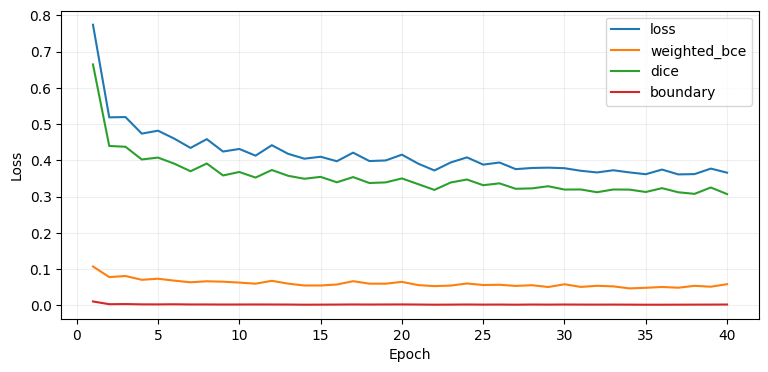

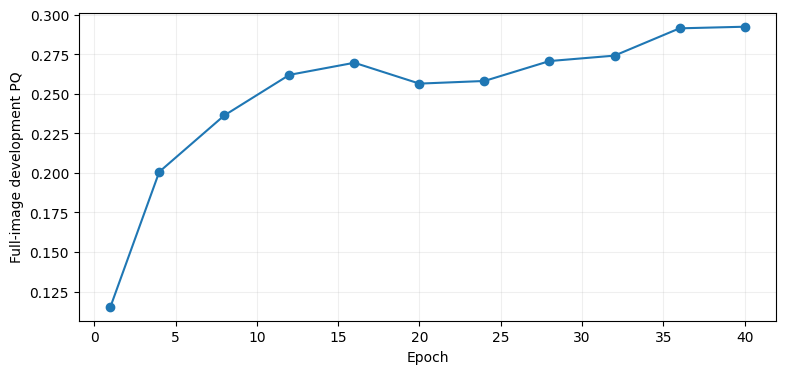

Best epoch: 40 Fixed-recipe dev PQ: 0.2923257758504731


In [26]:
if HISTORY:
    frame = pd.DataFrame(HISTORY)
    plt.figure(figsize=(9, 4))
    for column in ("loss", "weighted_bce", "dice", "boundary"):
        plt.plot(frame.epoch, frame[column], label=column)
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.2); plt.show()
    if "dev_pq" in frame:
        measured = frame.dropna(subset=["dev_pq"])
        plt.figure(figsize=(9, 4)); plt.plot(measured.epoch, measured.dev_pq, marker="o")
        plt.xlabel("Epoch"); plt.ylabel("Full-image development PQ"); plt.grid(alpha=0.2); plt.show()
BEST_PATH = RUN / "best.pt"
BEST_SHA = file_sha256(BEST_PATH)
BEST = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
if BEST["signature"] != training_signature(CFG):
    raise ValueError("Current settings/split differ from this checkpoint. Restore the saved config.")
MODEL.load_state_dict(BEST["state_dict"], strict=True)
MODEL.to(DEVICE).eval()
print("Best epoch:", BEST["epoch"], "Fixed-recipe dev PQ:", BEST["dev_pq"])

## Cell 21 - Tune threshold, minimum area and deterministic CLAHE on development data

This is a small post-processing search, not multiclass segmentation. Each threshold's connected components are computed once per image and reused for the different area cutoffs. Raw and fixed-CLAHE inference are evaluated independently with the same selected checkpoint; their thresholds are calibrated separately.

Default search: five thresholds x five minimum areas x two preprocessing modes. This can be reduced for a quick run. Caching both modes costs roughly 32 MiB per development image at float32. The winning settings are development-selected and must not be advertised as an unbiased test score.

In [27]:

CALIBRATION_ROWS = []
DEV_CACHES = {}

for mode in CFG.inference_modes:
    paths = cache_development_probabilities(
        MODEL, CFG, mode, BEST_SHA
    )

    DEV_CACHES[mode] = paths

    totals = {
        (float(t), int(a)): empty_stats()
        for t in CFG.thresholds
        for a in CFG.minimum_areas
    }

    for name, path in tqdm(
        paths.items(),
        desc=f"Calibrate PQ: {mode}",
    ):
        probability = np.load(
            path,
            mmap_mode="r",
            allow_pickle=False,
        )

        if probability.shape != tuple(CFG.expected_shape):
            raise ValueError(
                "Stale or invalid probability cache."
            )

        # Decode ground truth only once per image.
        gt = decoded_ground_truth(name)

        for threshold in CFG.thresholds:
            # Calculate connected components once per threshold.
            labels, areas = label_components(
                probability,
                threshold,
                CFG.connectivity,
            )

            # Reuse instance IoUs across all minimum-area values.
            results = score_labeled_file_areas(
                name,
                labels,
                areas,
                CFG.minimum_areas,
                gt,
            )

            for area, stats in results.items():
                add_stats(
                    totals[
                        (float(threshold), int(area))
                    ],
                    stats,
                )

    for (threshold, area), stats in totals.items():
        CALIBRATION_ROWS.append({
            "mode": mode,
            "threshold": threshold,
            "minimum_area": area,
            **summarize_stats(stats),
        })

CALIBRATION = pd.DataFrame(
    CALIBRATION_ROWS
)

CALIBRATION.to_csv(
    RUN / "development_calibration.csv",
    index=False,
)

WINNER = min(
    CALIBRATION_ROWS,
    key=lambda r: (
        -r["pq"],
        r["mode"] != "raw",
        abs(r["threshold"] - 0.5),
        abs(math.log2(r["minimum_area"] / 32)),
    ),
)

print(
    CALIBRATION.sort_values(
        "pq", ascending=False
    ).head(12).to_string(index=False)
)

print("Selected:", WINNER)

Cache dev: raw:   0%|          | 0/106 [00:00<?, ?it/s]

Calibrate PQ: raw:   0%|          | 0/106 [00:00<?, ?it/s]

Cache dev: clahe:   0%|          | 0/106 [00:00<?, ?it/s]

Calibrate PQ: clahe:   0%|          | 0/106 [00:00<?, ?it/s]

 mode  threshold  minimum_area    sum_iou  tp   fp  fn  records  ambiguous_gt  ambiguous_pred       pq       sq       rq
  raw        0.7           128 447.196531 678 1091 370      152             0               0 0.317498 0.659582 0.481363
  raw        0.5           128 455.735885 694 1144 354      152             0               0 0.315825 0.656680 0.480942
  raw        0.6           128 449.864687 681 1120 367      152             0               0 0.315805 0.660594 0.478062
clahe        0.6           128 458.442505 702 1172 346      152             0               0 0.313787 0.653052 0.480493
  raw        0.4           128 451.444189 690 1166 358      152             0               0 0.310912 0.654267 0.475207
clahe        0.7           128 450.571026 687 1174 361      152             0               0 0.309777 0.655853 0.472327
clahe        0.5           128 451.961385 691 1194 357      152             0               0 0.308191 0.654069 0.471190
  raw        0.5            64 4

## Cell 22 - Freeze the complete inference recipe

Freeze weights, grayscale normalization, full-frame CLAHE settings, tiling geometry, actual TTA passes, component connectivity, threshold and minimum area. No holdout or test labels select any of these choices. The model remains a one-output-channel binary model.

In [28]:
RECIPE = {
    "implementation": "sfsc-deeplabv3-clahe-v1",
    "architecture": "torchvision DeepLabV3-ResNet50; grayscale input=1; output logits=1",
    "checkpoint_sha256": BEST_SHA, "checkpoint_epoch": int(BEST["epoch"]),
    "annotation_sha256": ANN_SHA, "split_sha256": SPLIT_SHA,
    "metric": "global additive PQ; strict IoU > 0.5; maximum-IoU one-to-one assignment",
    "mode": WINNER["mode"], "threshold": float(WINNER["threshold"]),
    "minimum_area": int(WINNER["minimum_area"]), "connectivity": CFG.connectivity,
    "inference": inference_description(CFG, WINNER["mode"]),
    "development_pq": float(WINNER["pq"]), "training_config": asdict(CFG),
    "loss_definition": {"weighted_bce": 1.0, "dice": 1.0, "boundary": 0.2,
        "positive_bce_weight": CFG.positive_bce_weight, "boundary_radius": CFG.boundary_radius,
        "boundary_variant": "mean((sigmoid(logits)-target)*clipped_normalized_signed_distance)"},
}
RECIPE_SHA = object_hash(RECIPE)
write_json(RUN / "frozen_recipe.json", {"sha256": RECIPE_SHA, "recipe": RECIPE})

def assert_frozen_recipe():
    if file_sha256(BEST_PATH) != RECIPE["checkpoint_sha256"]:
        raise ValueError("Checkpoint changed after calibration.")
    if inference_description(CFG, RECIPE["mode"]) != RECIPE["inference"]:
        raise ValueError("Inference settings changed after calibration; do not reuse the frozen threshold.")
    if SPLIT_SHA != RECIPE["split_sha256"] or ANN_SHA != RECIPE["annotation_sha256"]:
        raise ValueError("Evaluation data changed after freezing.")
    # Reload to prevent an accidentally mutated in-memory network from being exported.
    checkpoint = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
    MODEL.load_state_dict(checkpoint["state_dict"], strict=True)
    MODEL.to(DEVICE).eval()

print("Frozen recipe hash:", RECIPE_SHA)

Frozen recipe hash: 50405ce5f942857adfaef8f6f7dfbe99aafed2ff05ae4da40d79abd7dd2abb8d


## Cell 23 - Evaluate the frozen holdout once

Do not tune from this output. If these images were already used by previous research, the result is not genuinely blind. A repeated execution reuses a report only when the exact recipe hash matches; a changed recipe requires an explicit new experiment, not silent overwriting.

Reported PQ uses the local reference convention described above. An ambiguous match graph is a reason to check the current organizer scorer, not to exploit an edge case.

In [29]:
assert_frozen_recipe()
HOLDOUT_PATH = RUN / "holdout_report.json"
if HOLDOUT_PATH.exists():
    HOLDOUT_REPORT = json.loads(HOLDOUT_PATH.read_text())
    if HOLDOUT_REPORT["recipe_sha256"] != RECIPE_SHA:
        raise RuntimeError("Holdout was already inspected under another recipe. Preserve that report and document a new experiment.")
    print("Reusing the existing frozen holdout report.")
else:
    summary, per_file, predictions = evaluate_model(MODEL, FILES["holdout"], CFG, RECIPE["mode"],
        RECIPE["threshold"], RECIPE["minimum_area"], save_predictions=True)
    HOLDOUT_REPORT = {"recipe_sha256": RECIPE_SHA, "summary": summary, "per_file": per_file,
                       "predictions": predictions, "note": "Not blind if these observations were used in prior research."}
    write_json(HOLDOUT_PATH, HOLDOUT_REPORT)
print("Frozen holdout results:", HOLDOUT_REPORT["summary"])

Full-image PQ (raw):   0%|          | 0/103 [00:00<?, ?it/s]

Frozen holdout results: {'sum_iou': 630.3005480600426, 'tp': 948, 'fp': 1255, 'fn': 400, 'records': 174, 'ambiguous_gt': 0, 'ambiguous_pred': 0, 'pq': 0.3549989006252, 'sq': 0.6648739958439268, 'rq': 0.5339341030695579}


## Cell 24 - Optional direct champion comparison

Set `champion_predictions_json` to a JSON mapping source filename to a list of COCO RLE dictionaries, including empty lists for images with no predictions. A wrapper with a `predictions` mapping is also accepted. Example:

`{"20140609195854Bh.jpeg": [{"size": [2048, 2048], "counts": "..."}]}`

The notebook re-scores both systems on identical holdout records and computes a paired bootstrap over the split's date/duplicate groups (or filename groups). This comparison is more meaningful than comparing a new split's PQ with the historical scalar 0.435179. The interval conditions on frozen model/selection choices and does not undo previous holdout reuse.

In [30]:
def paired_group_bootstrap(new_rows, old_rows, split_frame, n_resamples=2000, seed=42):
    names = [r["file_name"] for r in new_rows]
    new_map = {r["file_name"]: r for r in new_rows}
    old_map = {r["file_name"]: r for r in old_rows}
    group_map = dict(zip(split_frame.file_name, split_frame.group))
    groups = sorted({group_map[n] for n in names})
    keys = ("sum_iou", "tp", "fp", "fn")
    def grouped(mapping):
        return np.array([[sum(mapping[n][k] for n in names if group_map[n] == g) for k in keys]
                         for g in groups], dtype=float)
    a, b = grouped(new_map), grouped(old_map)
    def pq(values):
        d = values[..., 1] + 0.5 * (values[..., 2] + values[..., 3])
        return np.divide(values[..., 0], d, out=np.ones_like(d), where=d > 0)
    observed = float(pq(a.sum(0)) - pq(b.sum(0)))
    if len(groups) < 2:
        return {"delta_pq": observed, "ci95": None, "groups": len(groups)}
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(groups), size=(n_resamples, len(groups)))
    differences = pq(a[indices].sum(1)) - pq(b[indices].sum(1))
    return {"delta_pq": observed, "ci95": np.quantile(differences, [0.025, 0.975]).tolist(),
            "groups": len(groups), "resamples": n_resamples}

if CFG.champion_predictions_json:
    source = json.loads(Path(CFG.champion_predictions_json).read_text())
    source = source.get("predictions", source)
    champion = {}
    for key, value in source.items():
        name = canonical_filename(key)
        if name in champion: raise ValueError("Duplicate champion filename after canonicalization")
        champion[name] = value
    missing = set(FILES["holdout"]) - set(champion)
    if missing: raise ValueError(f"Champion predictions missing for {sorted(missing)[:10]}; include empty lists for no detections.")
    old_total, old_rows = empty_stats(), []
    for name in FILES["holdout"]:
        stats = score_file(name, champion[name]); add_stats(old_total, stats)
        old_rows.append({"file_name": name, **stats})
    comparison = {"champion": summarize_stats(old_total), "new": HOLDOUT_REPORT["summary"],
                  "paired_bootstrap": paired_group_bootstrap(HOLDOUT_REPORT["per_file"], old_rows, SPLIT, seed=CFG.seed)}
    write_json(RUN / "champion_comparison.json", comparison)
    print(json.dumps(comparison, indent=2))
else:
    print("No champion prediction file supplied. A direct champion-beating claim cannot be made.")

No champion prediction file supplied. A direct champion-beating claim cannot be made.


## Cell 25 - Predict all test images and export binary masks, instance masks and CSV

The official submission fields are `filament_id,segmentation_rle`, one row per predicted filament. The RLE field contains the ASCII counts string, not a Python bytes representation and not an RLE dictionary. Filament IDs use the unchanged image stem followed by `_1`, `_2`, etc.

An image with no predicted instances produces no fabricated filament row; it is still recorded in the processed-image manifest and gets an all-zero binary mask. Full-resolution binary masks and uint16 instance-ID masks are saved independently of the CSV. No network call submits the CSV.

In [31]:
assert_frozen_recipe()
EXPORT = RUN / "test_export"
for sub in ("binary_masks", "instance_masks"):
    (EXPORT / sub).mkdir(parents=True, exist_ok=True)
if CFG.save_test_probabilities: (EXPORT / "probabilities").mkdir(exist_ok=True)
if len({Path(n).stem for n in TEST_PATHS}) != len(TEST_PATHS):
    raise ValueError("Duplicate test image stems would produce ambiguous filament IDs.")
rows, processed = [], []
for name, path in tqdm(TEST_PATHS.items(), desc="Predict and export test set"):
    image = read_gray(path)
    if image.shape != tuple(CFG.expected_shape): raise ValueError(f"Wrong test image shape: {name}")
    probability = predict_full_image(MODEL, image, CFG, RECIPE["mode"])
    bank, labels = component_bank(probability, RECIPE["threshold"], RECIPE["minimum_area"],
                                  RECIPE["connectivity"], return_labels=True)
    stem = Path(name).stem
    Image.fromarray(((labels > 0) * 255).astype(np.uint8)).save(EXPORT / "binary_masks" / f"{stem}.png")
    Image.fromarray(labels.astype(np.uint16)).save(EXPORT / "instance_masks" / f"{stem}.png")
    if CFG.save_test_probabilities: np.save(EXPORT / "probabilities" / f"{stem}.npy", probability, allow_pickle=False)
    for index, item in enumerate(bank, start=1):
        rows.append({"filament_id": f"{stem}_{index}", "segmentation_rle": item["rle"]["counts"]})
    processed.append({"file_name": name, "filament_count": len(bank)})
SUBMISSION_PATH = EXPORT / "submission.csv"
submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
submission.to_csv(SUBMISSION_PATH, index=False)
write_json(EXPORT / "processed_images.json", {"recipe_sha256": RECIPE_SHA, "images": processed})
print("CSV:", SUBMISSION_PATH, "Predicted instances:", len(submission))
print("Images with zero predictions:", sum(r["filament_count"] == 0 for r in processed))
if not rows: warnings.warn("Every test image was predicted empty. Inspect training and calibration before any submission.")

Predict and export test set:   0%|          | 0/180 [00:00<?, ?it/s]

CSV: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3_clahe_v1/test_export/submission.csv Predicted instances: 2183
Images with zero predictions: 0


## Cell 26 - Round-trip audit of every exported mask

Read the actual saved CSV and decode every counts string. Check image identity, 2048-pixel shape, nonempty instances, disjoint predicted instances, PNG equivalence, and row counts. This verifies serialization, not semantic accuracy or official hidden scorer equivalence.

In [32]:
loaded = pd.read_csv(SUBMISSION_PATH, dtype=str, keep_default_na=False)
assert list(loaded.columns) == ["filament_id", "segmentation_rle"]
assert not loaded.filament_id.duplicated().any()
csv_by_stem = defaultdict(list)
for row in loaded.itertuples(index=False):
    stem, instance_id = row.filament_id.rsplit("_", 1)
    if not instance_id.isdigit() or int(instance_id) < 1: raise ValueError("Invalid filament id suffix")
    csv_by_stem[stem].append((int(instance_id), row.segmentation_rle))
expected_stems = {Path(r["file_name"]).stem for r in processed}
assert set(csv_by_stem).issubset(expected_stems)
assert {r["file_name"] for r in processed} == set(TEST_PATHS)
for record in tqdm(processed, desc="Audit CSV round-trip"):
    stem = Path(record["file_name"]).stem
    reconstructed = np.zeros(CFG.expected_shape, np.uint16)
    found = csv_by_stem.get(stem, [])
    assert len(found) == record["filament_count"]
    for instance_id, counts in found:
        mask = decode_mask({"size": list(CFG.expected_shape), "counts": counts})
        assert mask.shape == tuple(CFG.expected_shape) and mask.any()
        assert not np.any((reconstructed > 0) & mask), "Exported instances overlap"
        reconstructed[mask] = instance_id
    saved_labels = np.asarray(Image.open(EXPORT / "instance_masks" / f"{stem}.png"))
    saved_binary = np.asarray(Image.open(EXPORT / "binary_masks" / f"{stem}.png")) > 0
    assert np.array_equal(reconstructed, saved_labels)
    assert np.array_equal(reconstructed > 0, saved_binary)
write_json(EXPORT / "serialization_audit.json", {"passed": True, "images": len(processed),
           "instances": len(loaded), "submission_sha256": file_sha256(SUBMISSION_PATH), "recipe_sha256": RECIPE_SHA})
print("All exported masks passed the round-trip audit.")

Audit CSV round-trip:   0%|          | 0/180 [00:00<?, ?it/s]

All exported masks passed the round-trip audit.


## Cell 27 - Visual check after freezing

Inspect one holdout image after the recipe has been frozen. Ground-truth union is shown only for visualization; PQ above was calculated using the individual instance masks. Do not use this inspection to quietly retune the same claimed holdout result.

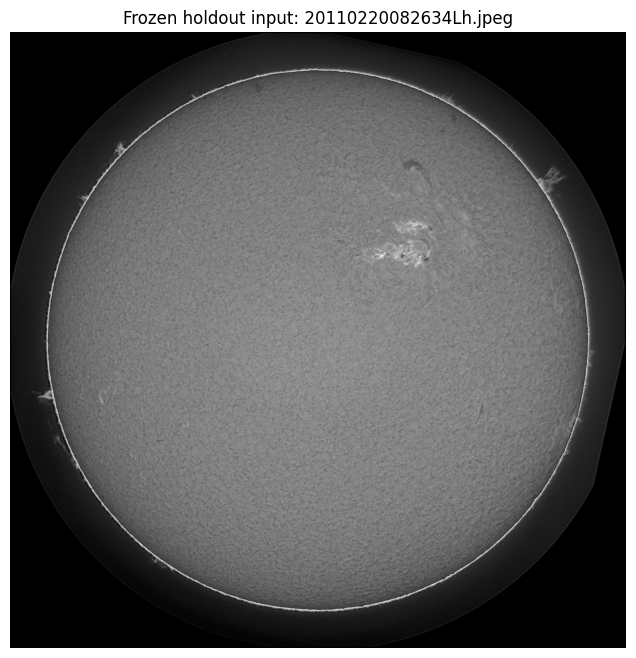

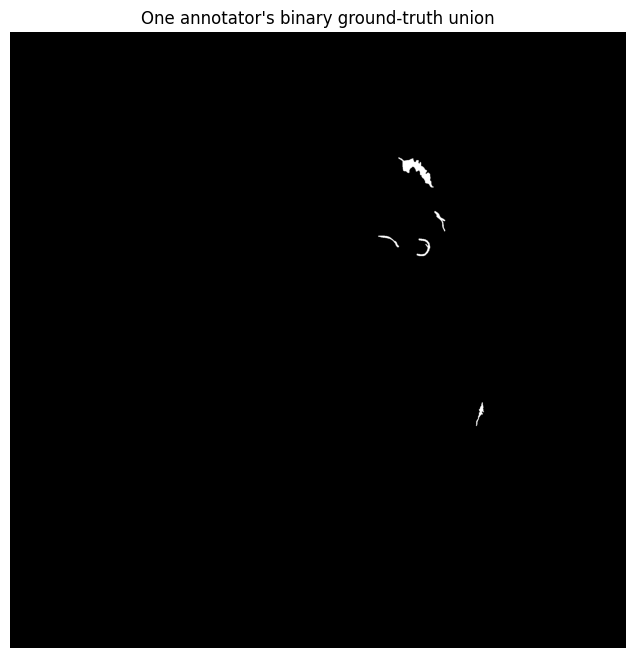

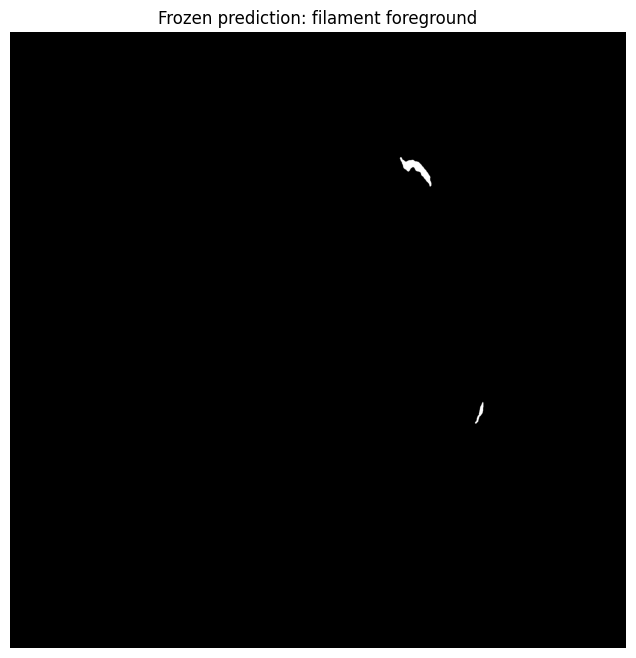

In [33]:
name = FILES["holdout"][0]
source = read_gray(TRAIN_PATHS[name])
gt_union, _ = cached_target(RECORDS_BY_FILE[name][0]["cache"])
pred_union = np.zeros(CFG.expected_shape, bool)
for rle in HOLDOUT_REPORT["predictions"][name]: pred_union |= decode_mask(rle)
for title, arr in [(f"Frozen holdout input: {name}", source),
                   ("One annotator's binary ground-truth union", gt_union),
                   ("Frozen prediction: filament foreground", pred_union)]:
    plt.figure(figsize=(8, 8)); plt.imshow(arr, cmap="gray"); plt.title(title); plt.axis("off"); plt.show()

## Cell 28 - Reusable single-image inference function

Use the frozen model and recipe on another original grayscale 2048-pixel JPEG. The returned binary mask is the simple segmentation output; instance IDs and RLEs are available for PQ/submission use. No additional training or manual prompts are needed.

In [34]:
def segment_image(path, save_binary_to=None):
    assert_frozen_recipe()
    image = read_gray(path)
    if image.shape != tuple(CFG.expected_shape):
        raise ValueError(f"Expected original image dimensions {CFG.expected_shape}; received {image.shape}")
    probability = predict_full_image(MODEL, image, CFG, RECIPE["mode"])
    bank, labels = component_bank(probability, RECIPE["threshold"], RECIPE["minimum_area"],
                                  RECIPE["connectivity"], return_labels=True)
    binary = (labels > 0).astype(np.uint8)
    if save_binary_to:
        destination = Path(save_binary_to); destination.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(binary * 255).save(destination)
    return {"probability": probability, "binary_mask": binary, "instance_labels": labels,
            "instances": [item["rle"] for item in bank]}

# Example after training:
# result = segment_image("/path/to/20140609195854Bh.jpeg", RUN / "example_binary.png")

## Cell 29 - Save environment and final run manifest

Archive the notebook together with the selected checkpoint, split, configuration, frozen recipe, calibration table, holdout report and CSV audit. Compare new ideas in separate run directories. CLAHE or a boundary loss is not a proven improvement until a controlled comparison supports a PQ gain.

In [35]:
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, check=False)
(RUN / "environment.txt").write_text(freeze.stdout)
manifest = {"recipe_sha256": RECIPE_SHA, "best_checkpoint_sha256": BEST_SHA,
            "submission_sha256": file_sha256(SUBMISSION_PATH),
            "development_pq_selected": float(WINNER["pq"]),
            "holdout_reference_pq": float(HOLDOUT_REPORT["summary"]["pq"]),
            "champion_comparison_available": bool(CFG.champion_predictions_json),
            "device": str(DEVICE), "python": platform.python_version(),
            "torch": torch.__version__, "torchvision": torchvision.__version__, "opencv": cv2.__version__,
            "notebook_loss_weights": [1.0, 1.0, 0.2],
            "test_images_processed": len(processed), "test_instances": len(loaded)}
write_json(RUN / "run_manifest.json", manifest)
print(json.dumps(manifest, indent=2))
print("Save the complete run directory:", RUN)

{
  "recipe_sha256": "50405ce5f942857adfaef8f6f7dfbe99aafed2ff05ae4da40d79abd7dd2abb8d",
  "best_checkpoint_sha256": "2889b021c4e14dd4ec70f2ea8d79b70848d2415014005118e69f5d70bf4c33c1",
  "submission_sha256": "4325b8e048b64d1b64cc45b169059b97c27e51ee6af3444accd8858d138f7570",
  "development_pq_selected": 0.31749842463139727,
  "holdout_reference_pq": 0.3549989006252,
  "champion_comparison_available": false,
  "device": "cuda",
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "opencv": "4.14.0",
  "notebook_loss_weights": [
    1.0,
    1.0,
    0.2
  ],
  "test_images_processed": 180,
  "test_instances": 2183
}
Save the complete run directory: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3_clahe_v1


## Sources and implementation notes

The user's dataset description and loss screenshot define the task, grayscale input, annotation structure and outer loss weights. They do not establish a best CLAHE strength, BCE class weight, boundary-loss variant, crop size, or achievable PQ. Those settings are explicit choices in this notebook.

1. DeepLabV3 paper: Chen et al., *Rethinking Atrous Convolution for Semantic Image Segmentation*, 2017. https://arxiv.org/abs/1706.05587
2. Official torchvision DeepLabV3 source, including the pretrained builder and dilated ResNet: https://docs.pytorch.org/vision/stable/_modules/torchvision/models/segmentation/deeplabv3.html
3. OpenCV CLAHE example and contrast-limiting explanation: https://docs.opencv.org/3.0-rc1/d5/daf/tutorial_py_histogram_equalization.html ; current API: https://docs.opencv.org/4.x/d6/db6/classcv_1_1CLAHE.html
4. PyTorch binary cross-entropy with logits: https://docs.pytorch.org/docs/main/generated/torch.nn.functional.binary_cross_entropy_with_logits.html
5. Kervadec et al., *Boundary loss for highly unbalanced segmentation*, MIDL 2019: https://proceedings.mlr.press/v102/kervadec19a.html ; official implementation: https://github.com/LIVIAETS/boundary-loss
6. COCO mask utilities: https://github.com/ppwwyyxx/cocoapi/blob/master/PythonAPI/pycocotools/mask.py
7. Competition task, metric update and exact submission fields: https://www.kaggle.com/competitions/filament-segmentation-2026/overview/final-submission
8. Dataset format: https://www.kaggle.com/competitions/filament-segmentation-2026/data

The boundary implementation is inspired by the signed-distance formulation, but its clipping, scaling, target-only offset and empty-mask convention are explicitly documented adaptations. Published medical-image results are not claims about SFSC performance. The local evaluator convention is disclosed rather than represented as certified hidden-evaluator parity.